# DỰ ĐOÁN ĐỘ TRỄ MẠNG (RTT - Round Trip Time)

## 1. Giới thiệu bài toán
Mục tiêu của bài toán là dự đoán độ trễ trung bình khi gửi và nhận gói tin tới máy chủ đích (`rtt_avg_ms`) dựa trên các đặc trưng về mạng (Network features) và thời gian (Time features).

## 2. Định nghĩa Input (X) và Output (Y)

### 🔹 INPUT (X) - Các đặc trưng đầu vào:
| Feature | Ý nghĩa |
| :--- | :--- |
| `gateway_rtt_avg_ms` | Độ trễ trung bình tới Gateway |

### 🔸 OUTPUT (Y) - Biến mục tiêu:
| Feature | Ý nghĩa |
| :--- | :--- |
| `rtt_avg_ms` | Độ trễ trung bình khi gửi và nhận gói tin tới máy chủ đích (đơn vị milliseconds - ms) |

In [1]:
# Cell 1: Đọc dữ liệu cục bộ (Chỉ lấy 1 feature Input)

import os
import pandas as pd

# 1. Tạo thư mục chứa hình ảnh xuất ra cho báo cáo LaTeX
os.makedirs('figures', exist_ok=True)

# 2. Đọc trực tiếp file dataset.csv đặt cùng thư mục với notebook
download_path = 'dataset.csv'
if not os.path.exists(download_path):
    raise FileNotFoundError(
        "Không tìm thấy dataset.csv trong thư mục dự án. "
        "Hãy đặt file dữ liệu cạnh notebook trước khi chạy."
    )

# 3. Đọc dữ liệu
try:
    df = pd.read_csv(download_path)
    print(f"\nKích thước dữ liệu: {df.shape[0]} dòng, {df.shape[1]} cột.")
    display(df.head())

    X_feature = ['gateway_rtt_avg_ms']
    target_y = 'rtt_avg_ms'

    print("\n--- Kiểm tra sự tồn tại của các cột ---")
    required_cols = X_feature + [target_y]
    missing_cols = [col for col in required_cols if col not in df.columns]

    if missing_cols:
        print(f"⚠️ Cảnh báo: Các cột sau không tìm thấy trong file: {missing_cols}")
    else:
        print(f"✅ Đã tìm thấy cột Input: {X_feature}")
        print(f"✅ Đã tìm thấy cột Output: {target_y}")
except Exception as e:
    print(f"Có lỗi khi đọc file: {e}")
    raise



Kích thước dữ liệu: 54617 dòng, 67 cột.


C:\Users\dinht\AppData\Local\Temp\ipykernel_12780\4009030794.py:19: DtypeWarning: Columns (47: wifi_phy) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(download_path)


,run_id,host_label,sample_index,timestamp_utc,timestamp_local,epoch_s,elapsed_s,link_type,gateway_ip,dns_server,...,sample_duration_s,label_outage,label_packet_loss,label_high_latency,label_high_jitter,label_gateway_degraded,label_anomaly,event_category,event_description,notes
0,desktop-eth_20260920_123407,desktop-eth,0,2026-09-20T16:34:22Z,2026-09-20T12:34:22-04:00,1789922062,0.0,unknown,192.168.1.1,192.168.1.1,...,65.70,0,0,0,0,0,0,NaN,NaN,NaN
1,desktop-eth_20260920_123407,desktop-eth,1,2026-09-20T16:35:52Z,2026-09-20T12:35:52-04:00,1789922152,90.0,unknown,192.168.1.1,192.168.1.1,...,12.41,0,1,0,0,0,1,NaN,NaN,NaN
2,desktop-eth_20260920_123407,desktop-eth,2,2026-09-20T16:36:22Z,2026-09-20T12:36:22-04:00,1789922182,120.0,unknown,192.168.1.1,192.168.1.1,...,10.20,0,0,0,0,0,0,NaN,NaN,NaN
3,desktop-eth_20260920_123407,desktop-eth,3,2026-09-20T16:36:52Z,2026-09-20T12:36:52-04:00,1789922212,150.0,unknown,192.168.1.1,192.168.1.1,...,9.32,0,0,0,0,0,0,NaN,NaN,NaN
4,desktop-eth_20260920_123407,desktop-eth,4,2026-09-20T16:37:22Z,2026-09-20T12:37:22-04:00,1789922242,180.0,unknown,192.168.1.1,192.168.1.1,...,11.07,0,0,1,1,0,1,NaN,NaN,NaN



--- Kiểm tra sự tồn tại của các cột ---
✅ Đã tìm thấy cột Input: ['gateway_rtt_avg_ms']
✅ Đã tìm thấy cột Output: rtt_avg_ms


In [2]:
from sklearn.model_selection import train_test_split
X, y = df[X_feature], df[target_y]
# Làm sạch dữ liệu null trực tiếp trên X và y bằng Pandas
clean_data = pd.concat([X, y], axis=1).dropna()
X, y = clean_data[X_feature], clean_data[target_y]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#2. Khám phá và trực quan hóa tập dữ liệu:


In [3]:
# Cell 2: Không cần cài thêm thư viện datasets vì dữ liệu đọc từ dataset.csv
print("Bỏ qua bước cài đặt datasets: dữ liệu đã có sẵn trong dataset.csv.")


Bỏ qua bước cài đặt datasets: dữ liệu đã có sẵn trong dataset.csv.


--- PHẦN 2: EDA VÀ TRỰC QUAN HÓA (XỬ LÝ OUTLIERS) ---
Kích thước dữ liệu sạch sau khi loại bỏ null cho EDA: (54589, 5)


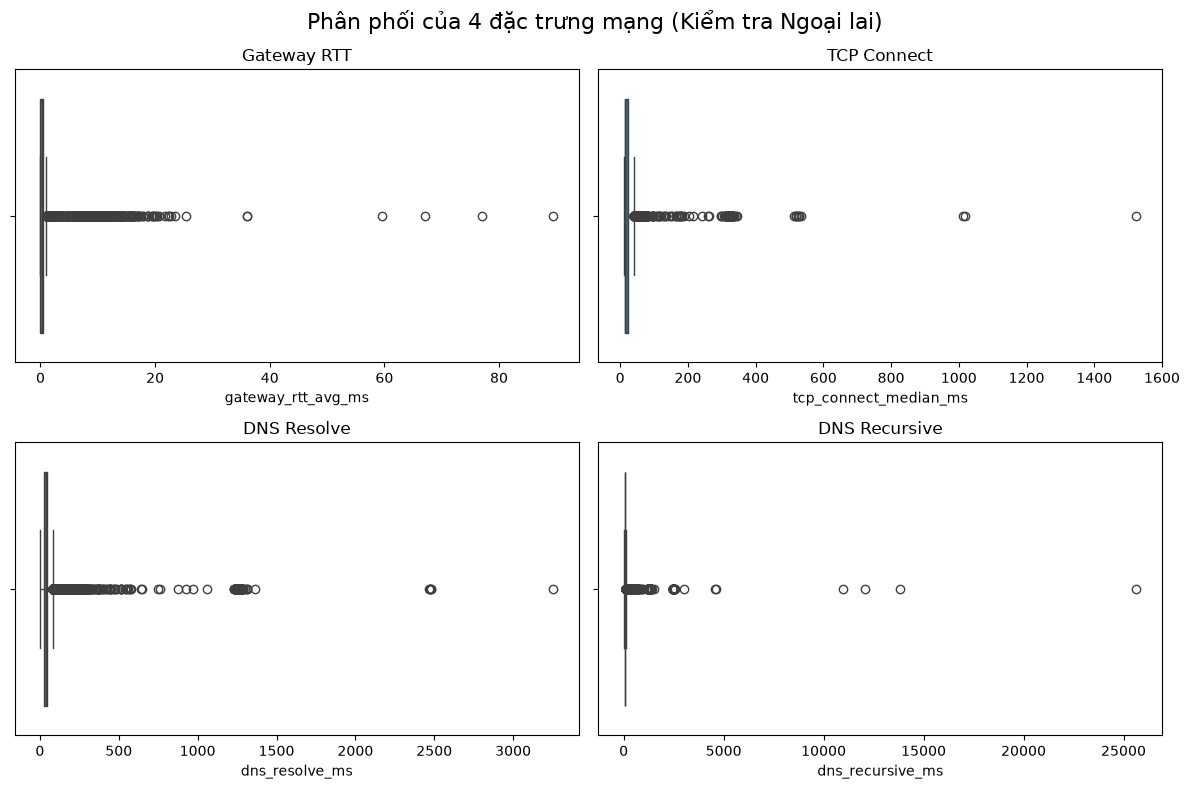

=> ĐÃ LƯU SƠ ĐỒ PHÂN PHỐI: figures/eda_distributions.png

--- HỆ SỐ TƯƠNG QUAN PEARSON ---
rtt_avg_ms               1.000000
tcp_connect_median_ms    0.252810
gateway_rtt_avg_ms       0.197710
dns_recursive_ms         0.040121
dns_resolve_ms           0.029868
Name: rtt_avg_ms, dtype: float64


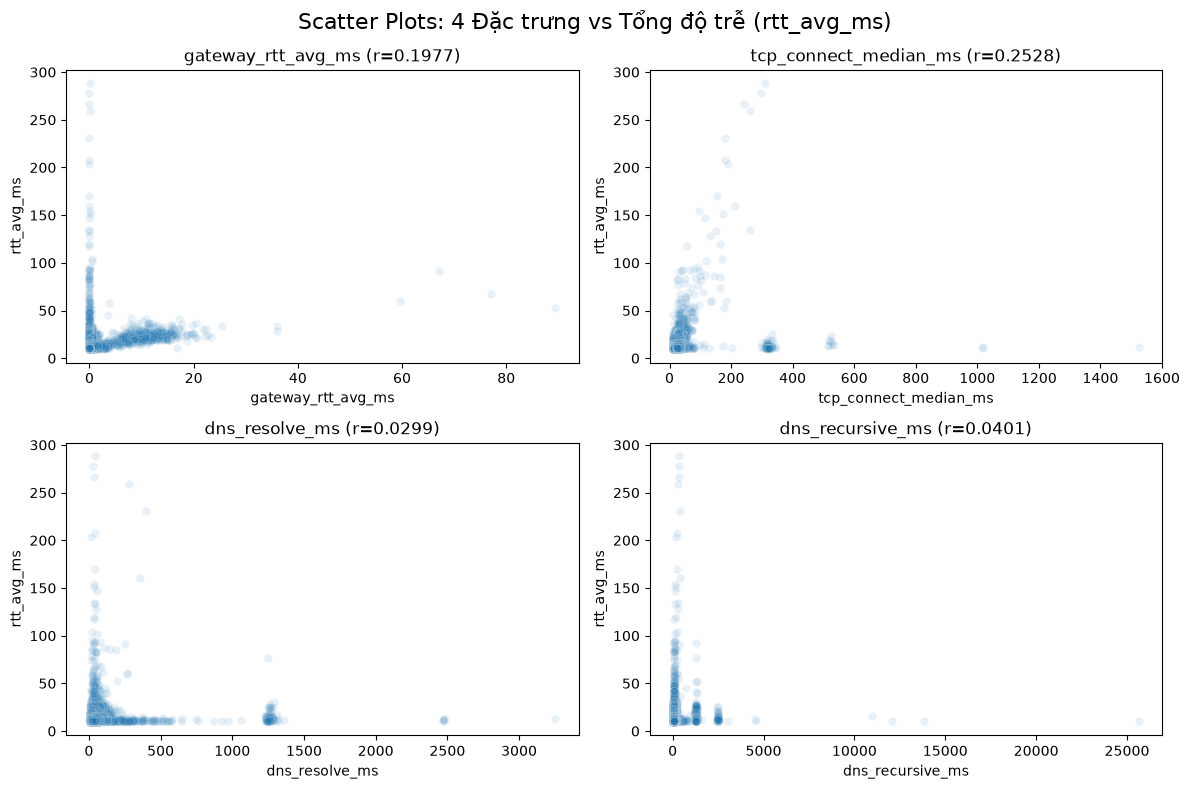

=> ĐÃ LƯU SƠ ĐỒ SCATTER: figures/Task2_Compare_4_Features_ScatterPlots.png và figures/scatter_plot.png


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

print("--- PHẦN 2: EDA VÀ TRỰC QUAN HÓA (XỬ LÝ OUTLIERS) ---")

# Khắc phục lỗi: Tạo biến df_clean bằng cách lấy 4 đặc trưng mạng + cột target từ df gốc và loại bỏ null
features_for_eda = ['gateway_rtt_avg_ms', 'tcp_connect_median_ms', 'dns_resolve_ms', 'dns_recursive_ms', 'rtt_avg_ms']
try:
    df_clean = df[features_for_eda].dropna().copy()
    print(f"Kích thước dữ liệu sạch sau khi loại bỏ null cho EDA: {df_clean.shape}")
except NameError:
    print(" LỖI CRITICAL: Không tìm thấy biến 'df' gốc!")
    print(" Cách sửa: Anh phải cuộn lên CÁC CELL ĐẦU TIÊN (Phần 1. Đọc dữ liệu) và CHẠY LẠI CHÚNG để nạp data vào bộ nhớ trước khi chạy Cell này!")
    raise
except KeyError as e:
    print(f"\n LỖI: Thiếu cột {e} trong dữ liệu gốc!")
    print(" Cách sửa: Ở Cell 1, anh đang lỡ dùng code xóa mất các cột này rồi. Hãy sửa Cell 1 để nạp TOÀN BỘ các cột nhé!")
    raise

# 1. Vẽ sơ đồ phân phối (Boxplots) để phân tích Outliers
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Phân phối của 4 đặc trưng mạng (Kiểm tra Ngoại lai)', fontsize=16)

sns.boxplot(ax=axes[0, 0], x=df_clean['gateway_rtt_avg_ms']).set_title('Gateway RTT')
sns.boxplot(ax=axes[0, 1], x=df_clean['tcp_connect_median_ms']).set_title('TCP Connect')
sns.boxplot(ax=axes[1, 0], x=df_clean['dns_resolve_ms']).set_title('DNS Resolve')
sns.boxplot(ax=axes[1, 1], x=df_clean['dns_recursive_ms']).set_title('DNS Recursive')

plt.tight_layout()
plt.savefig('figures/eda_distributions.png', dpi=300)
plt.show()
print("=> ĐÃ LƯU SƠ ĐỒ PHÂN PHỐI: figures/eda_distributions.png")

# 2. In hệ số tương quan Pearson
print("\n--- HỆ SỐ TƯƠNG QUAN PEARSON ---")
correlations = df_clean.corr()['rtt_avg_ms'].sort_values(ascending=False)
print(correlations)

# 3. Vẽ sơ đồ Scatter Plots hình chữ L
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
fig.suptitle('Scatter Plots: 4 Đặc trưng vs Tổng độ trễ (rtt_avg_ms)', fontsize=16)

sns.scatterplot(ax=axes[0, 0], x=df_clean['gateway_rtt_avg_ms'], y=df_clean['rtt_avg_ms'], alpha=0.1)
axes[0, 0].set_title(f"gateway_rtt_avg_ms (r={correlations['gateway_rtt_avg_ms']:.4f})")

sns.scatterplot(ax=axes[0, 1], x=df_clean['tcp_connect_median_ms'], y=df_clean['rtt_avg_ms'], alpha=0.1)
axes[0, 1].set_title(f"tcp_connect_median_ms (r={correlations['tcp_connect_median_ms']:.4f})")

sns.scatterplot(ax=axes[1, 0], x=df_clean['dns_resolve_ms'], y=df_clean['rtt_avg_ms'], alpha=0.1)
axes[1, 0].set_title(f"dns_resolve_ms (r={correlations['dns_resolve_ms']:.4f})")

sns.scatterplot(ax=axes[1, 1], x=df_clean['dns_recursive_ms'], y=df_clean['rtt_avg_ms'], alpha=0.1)
axes[1, 1].set_title(f"dns_recursive_ms (r={correlations['dns_recursive_ms']:.4f})")

plt.tight_layout()
plt.savefig('figures/Task2_Compare_4_Features_ScatterPlots.png', dpi=300)
plt.savefig('figures/scatter_plot.png', dpi=300)
plt.show()
print("=> ĐÃ LƯU SƠ ĐỒ SCATTER: figures/Task2_Compare_4_Features_ScatterPlots.png và figures/scatter_plot.png")

In [5]:
print("\n--- CÁC TỨ PHÂN VỊ (Q1, Q2, Q3) CỦA 4 ĐẶC TRƯNG ---")
features = ['gateway_rtt_avg_ms', 'tcp_connect_median_ms', 'dns_resolve_ms', 'dns_recursive_ms']

for col in features:
    q1 = df_clean[col].quantile(0.25)
    q2 = df_clean[col].quantile(0.50)
    q3 = df_clean[col].quantile(0.75)
    print(f"[{col}]")
    print(f"  Q1 (25%): {q1:.2f} ms")
    print(f"  Q2 (50% - Median): {q2:.2f} ms")
    print(f"  Q3 (75%): {q3:.2f} ms")
    print("-" * 30)


--- CÁC TỨ PHÂN VỊ (Q1, Q2, Q3) CỦA 4 ĐẶC TRƯNG ---
[gateway_rtt_avg_ms]
  Q1 (25%): 0.00 ms
  Q2 (50% - Median): 0.20 ms
  Q3 (75%): 0.40 ms
------------------------------
[tcp_connect_median_ms]
  Q1 (25%): 12.97 ms
  Q2 (50% - Median): 14.48 ms
  Q3 (75%): 23.94 ms
------------------------------
[dns_resolve_ms]
  Q1 (25%): 27.03 ms
  Q2 (50% - Median): 36.02 ms
  Q3 (75%): 48.19 ms
------------------------------
[dns_recursive_ms]
  Q1 (25%): 47.21 ms
  Q2 (50% - Median): 59.24 ms
  Q3 (75%): 72.50 ms
------------------------------


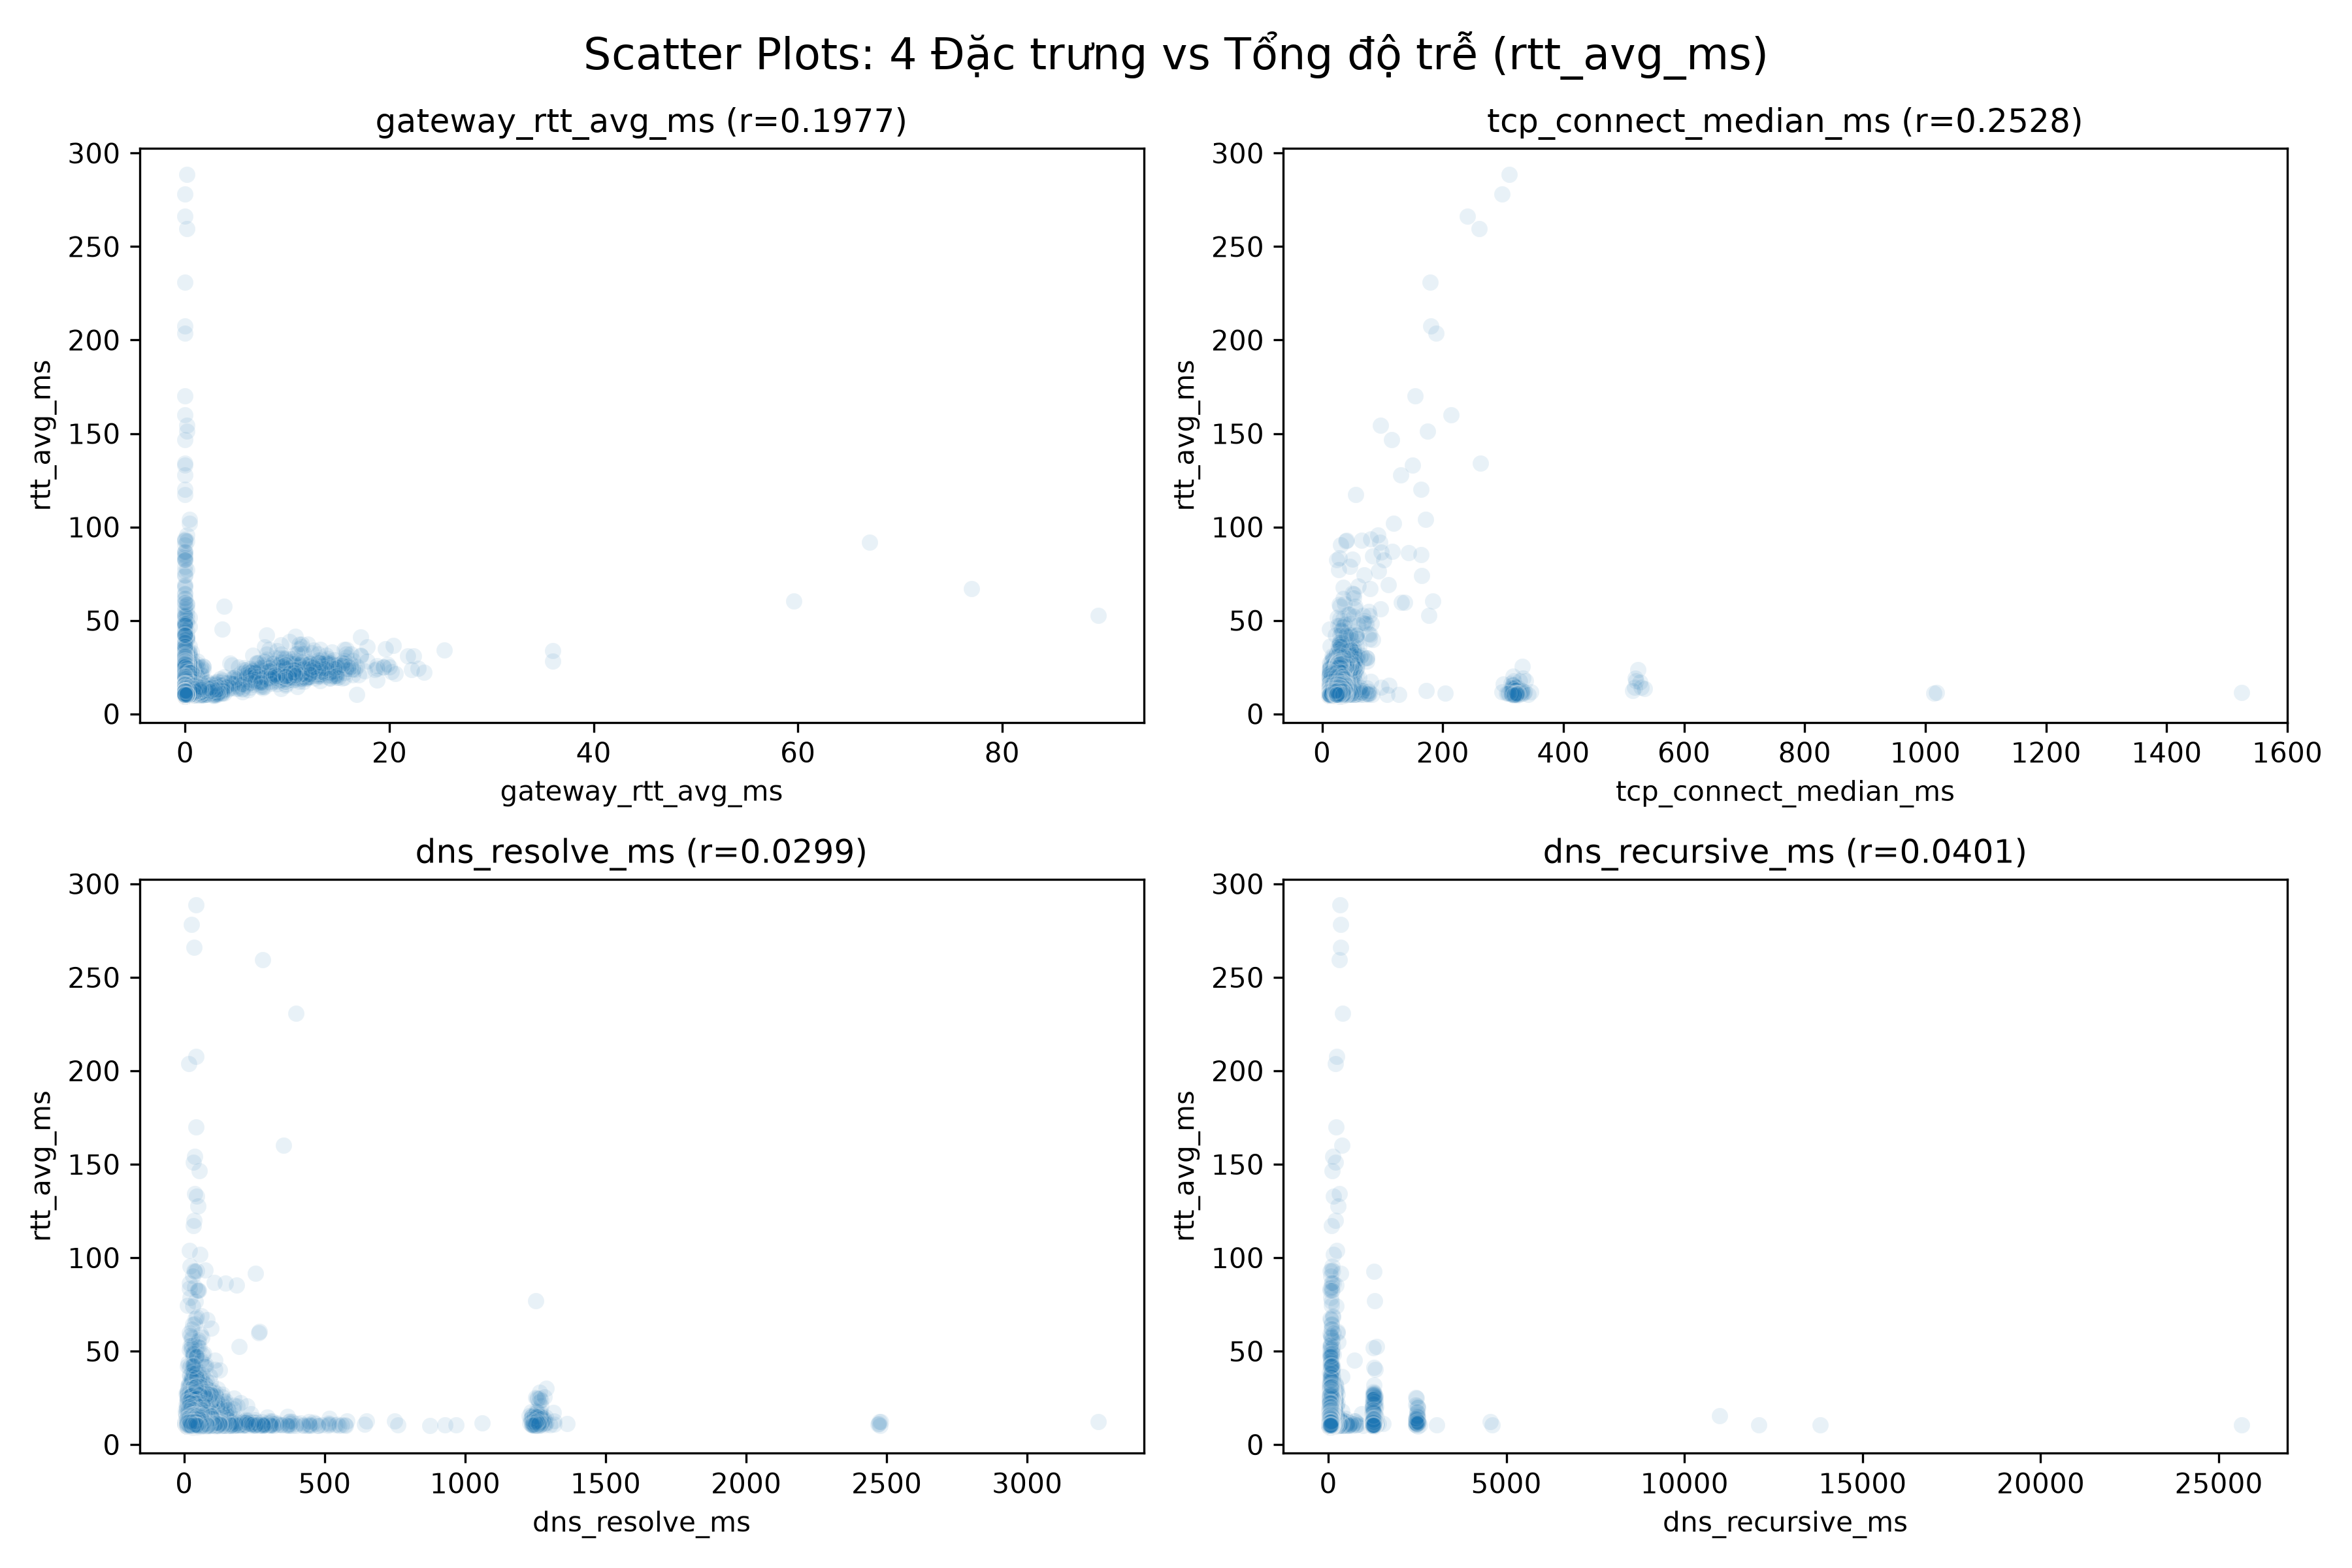

In [6]:
import os
from IPython.display import Image, display

image_path = 'figures/Task2_Compare_4_Features_ScatterPlots.png'
if os.path.exists(image_path):
    display(Image(image_path))
else:
    print(f"⚠️ Cảnh báo: File ảnh '{image_path}' chưa được tạo.")
    print("Lý do: Cell EDA phía trên (ID: 522fuUCAsuXN) bị lỗi do biến 'df_clean' chưa được định nghĩa.")

### 3. Tính hàm mất mát bình phương trung bình (MSE Cost Function $J(\theta)$)

Mô hình hồi quy tuyến tính đơn biến có dạng:
$$f_{\theta}(x) = \theta_0 + \theta_1 x_1 = X\theta$$

Hàm mất mát đo lường sai số giữa giá trị dự đoán $f_{\theta}(x^{(i)})$ và giá trị thực tế $y^{(i)}$ trên tập dữ liệu gồm $n$ quan sát:
$$J(\theta) = \frac{1}{2n}\sum_{i=1}^{n}\left(f_{\theta}(x^{(i)}) - y^{(i)}\right)^2 = \frac{1}{2n}\|X\theta - y\|_2^2$$

In [7]:
# Cell 3: Tính hàm mất mát MSE J(theta) dựa trên tập Train
import numpy as np

# 1. TẠO MA TRẬN THIẾT KẾ VÀ DỌN DẸP DỮ LIỆU RỖNG
# TRỌNG TÂM FIX LỖI TRÀN RAM: Ép cả x và y về mảng 1 chiều (flatten) TRƯỚC khi so sánh
# để tránh lỗi NumPy tự động tạo ma trận khổng lồ (Broadcasting) n x n.
x_flat = np.array(X_train).astype(float).flatten()
y_flat = np.array(y_train).astype(float).flatten()

# Tìm và loại bỏ các hàng bị thiếu dữ liệu (NaN) trên 2 mảng 1 chiều (kích thước 1-1)
# valid_mask = ~np.isnan(x_flat) & ~np.isnan(y_flat)

# Lọc lấy các giá trị sạch
x_clean = x_flat[:]
y_clean = y_flat[:]
n_train_samples = len(y_clean)

# Đưa y_clean trở lại dạng vector cột (n, 1) để nhân ma trận
y_train_vec = y_clean.reshape(-1, 1)

# Thêm cột số 1 vào đằng trước x_clean để khớp với hệ số chặn theta_0
X_train_design = np.column_stack((np.ones(n_train_samples), x_clean))

print(f"Số lượng mẫu Train (đã dọn sạch lỗi rỗng): {n_train_samples}")
print(f"Kích thước X_train_design: {X_train_design.shape}")
print(f"Kích thước y_train_vec: {y_train_vec.shape}")

# 2. HÀM TÍNH COST
def compute_cost(feat_matrix, target_vector, theta_params):
    num_samples = len(target_vector)
    predictions = feat_matrix @ theta_params
    errors = predictions - target_vector
    cost = (1 / (2 * num_samples)) * np.sum(errors ** 2)
    return float(cost)

# Khởi tạo theta ban đầu và tính thử cost trên tập Train
theta_start = np.zeros((2, 1))
initial_cost = compute_cost(X_train_design, y_train_vec, theta_start)
print(f"Giá trị Cost ban đầu J(theta) trên tập Train: {initial_cost:.6f}")

Số lượng mẫu Train (đã dọn sạch lỗi rỗng): 43679
Kích thước X_train_design: (43679, 2)
Kích thước y_train_vec: (43679, 1)
Giá trị Cost ban đầu J(theta) trên tập Train: 92.167763


### 4. Cài đặt thuật toán Gradient Descent

Quy tắc cập nhật tham số ngược hướng đạo hàm với tốc độ học (learning rate) $\gamma > 0$:
$$\theta := \theta - \gamma \nabla_{\theta}J(\theta)^\top$$

Trong đó vector đạo hàm riêng được biểu diễn dưới dạng ma trận:
$$\nabla_{\theta}J(\theta)^\top = \frac{1}{n}X^\top(X\theta - y)$$

In [8]:
# Cell 4: Thực thi Gradient Descent trên tập Train
def gradient_descent(feat_matrix, target_vector, theta_init, learning_rate=0.0001, num_iterations=1000):
    num_samples = len(target_vector)
    theta_current = theta_init.copy().astype(float)
    cost_history = []
    theta_history = [theta_current.copy()]

    for i in range(1, num_iterations + 1):
        # Tính sai số: h(x) - y
        errors = (feat_matrix @ theta_current) - target_vector

        # Đạo hàm Gradient
        grad = (1 / num_samples) * (feat_matrix.T @ errors)

        # Cập nhật theta
        theta_current = theta_current - learning_rate * grad

        # Lưu lịch sử
        current_cost = compute_cost(feat_matrix, target_vector, theta_current)
        cost_history.append(current_cost)
        theta_history.append(theta_current.copy())

        if i in [1, 2, 3, 100, 500, num_iterations]:
            print(f"Vòng {i:4d} | theta_0 = {theta_current[0,0]:.6f}, theta_1 = {theta_current[1,0]:.6f} | J = {current_cost:.6f}")

    return theta_current, np.array(cost_history), np.array(theta_history)

# TRỌNG TÂM SỬA LỖI NaN: Hạ learning_rate xuống cực nhỏ (0.0001) và tăng vòng lặp lên 1000
theta_gd, cost_hist_gd, theta_hist_gd = gradient_descent(
    X_train_design, y_train_vec, theta_start, learning_rate=0.01, num_iterations=1000
)

print("\n=== KẾT QUẢ GRADIENT DESCENT (TRAIN SET) ===")
print(f"Theta tối ưu: {theta_gd.flatten()}")

Vòng    1 | theta_0 = 0.125830, theta_1 = 0.054541 | J = 90.299749
Vòng    2 | theta_0 = 0.250225, theta_1 = 0.107706 | J = 88.482058
Vòng    3 | theta_0 = 0.373205, theta_1 = 0.159524 | J = 86.713149
Vòng  100 | theta_0 = 7.689165, theta_1 = 1.721454 | J = 22.496615
Vòng  500 | theta_0 = 12.188765, theta_1 = 0.875988 | J = 12.431996
Vòng 1000 | theta_0 = 12.313184, theta_1 = 0.831447 | J = 12.424097

=== KẾT QUẢ GRADIENT DESCENT (TRAIN SET) ===
Theta tối ưu: [12.31318397  0.83144724]


### 5. Nghiệm giải tích bình phương tối thiểu (Analytical Least-Squares Solution)

Cho đạo hàm bằng $0$ ($\nabla_{\theta}J(\theta) = 0$), ta thu được hệ Phương trình chuẩn (Normal Equations):
$$(X^\top X)\theta = X^\top y \implies \theta^* = (X^\top X)^{-1} X^\top y$$

In [9]:
# Cell 5: Nghiệm giải tích Normal Equation trên tập Train
def compute_analytical_solution(feat_matrix, target_vector):
    mat_T_mat = feat_matrix.T @ feat_matrix
    mat_T_vec = feat_matrix.T @ target_vector
    theta_exact = np.linalg.inv(mat_T_mat) @ mat_T_vec
    return theta_exact, mat_T_mat, mat_T_vec

theta_analytical, mat_T_mat, mat_T_vec = compute_analytical_solution(X_train_design, y_train_vec)
cost_analytical = compute_cost(X_train_design, y_train_vec, theta_analytical)

print("=== SO SÁNH HAI PHƯƠNG PHÁP TRÊN TẬP TRAIN ===")
print(f"Theta Gradient Descent : {theta_gd.flatten()}")
print(f"Theta Normal Equation  : {theta_analytical.flatten()}")
print(f"Sai lệch hàm Cost      : {abs(cost_hist_gd[-1] - cost_analytical):.2e}")

=== SO SÁNH HAI PHƯƠNG PHÁP TRÊN TẬP TRAIN ===
Theta Gradient Descent : [12.31318397  0.83144724]
Theta Normal Equation  : [12.31467254  0.83090994]
Sai lệch hàm Cost      : 1.11e-06


## 6. Cost function landscape and optimization trajectory

CHI TIẾT QUÁ TRÌNH TỐI ƯU HÓA 
--- ĐIỂM BẮT ĐẦU (Vòng 0) ---
  Theta_0 : 0.000000
  Theta_1 : 0.000000
  Cost J  : 92.167763

--- ĐIỂM KẾT THÚC (Vòng 1000) ---
  Theta_0 : 12.313184
  Theta_1 : 0.831447
  Cost J  : 12.424097

--- NGHIỆM CHÍNH XÁC (Analytical) ---
  Theta_0 : 12.314673
  Theta_1 : 0.830910
  Cost J  : 12.424096

--- SAI LỆCH CUỐI CÙNG (GD vs Analytical) ---
  Delta Theta_0 : 0.001489
  Delta Theta_1 : 0.000537
  Delta Cost    : 0.000001



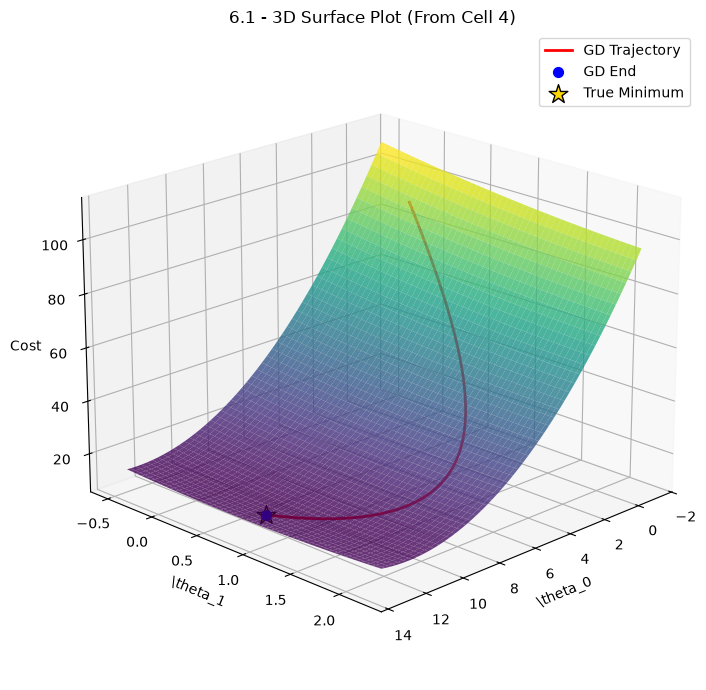

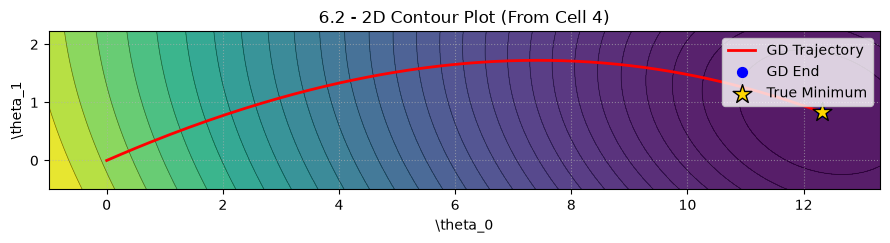

Saved: figures/cost_surface.png, figures/cost_contour.png


In [10]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# PHẦN 1: LẤY DỮ LIỆU TỪ CELL 4 & NGHIỆM CHÍNH XÁC
# ==========================================
# Lấy quỹ đạo theta từ Cell 4
t0_hist = theta_hist_gd[:, 0, 0]
t1_hist = theta_hist_gd[:, 1, 0]

# Lấy lịch sử cost từ Cell 4 và thêm điểm bắt đầu (vòng 0)
cost_init = compute_cost(X_train_design, y_train_vec, theta_start)
cost_hist_full = np.insert(cost_hist_gd, 0, cost_init)

# Tính nghiệm chính xác (Analytical) để làm tâm đồ thị
theta_analytical = np.linalg.inv(X_train_design.T @ X_train_design) @ (X_train_design.T @ y_train_vec)
cost_analytical = compute_cost(X_train_design, y_train_vec, theta_analytical)

center_t0 = theta_analytical[0, 0]
center_t1 = theta_analytical[1, 0]


# ==========================================
# [MỚI] PHẦN LOG CHI TIẾT ĐẦU VÀ CUỐI
# ==========================================
print("="*55)
print("CHI TIẾT QUÁ TRÌNH TỐI ƯU HÓA ")
print("="*55)
print("--- ĐIỂM BẮT ĐẦU (Vòng 0) ---")
print(f"  Theta_0 : {t0_hist[0]:.6f}")
print(f"  Theta_1 : {t1_hist[0]:.6f}")
print(f"  Cost J  : {cost_init:.6f}")

print(f"\n--- ĐIỂM KẾT THÚC (Vòng {len(t0_hist)-1}) ---")
print(f"  Theta_0 : {t0_hist[-1]:.6f}")
print(f"  Theta_1 : {t1_hist[-1]:.6f}")
print(f"  Cost J  : {cost_hist_full[-1]:.6f}")

print("\n--- NGHIỆM CHÍNH XÁC (Analytical) ---")
print(f"  Theta_0 : {center_t0:.6f}")
print(f"  Theta_1 : {center_t1:.6f}")
print(f"  Cost J  : {cost_analytical:.6f}")

print("\n--- SAI LỆCH CUỐI CÙNG (GD vs Analytical) ---")
print(f"  Delta Theta_0 : {abs(t0_hist[-1] - center_t0):.6f}")
print(f"  Delta Theta_1 : {abs(t1_hist[-1] - center_t1):.6f}")
print(f"  Delta Cost    : {abs(cost_hist_full[-1] - cost_analytical):.6f}")
print("="*55 + "\n")


# ==========================================
# PHẦN 2: TẠO LƯỚI KHÔNG GIAN (GRID)
# ==========================================
# Vì quỹ đạo của Cell 4 đi từ 0 đến ~12.3, ta cần lưới bao quát đủ rộng
t0_vals = np.linspace(min(t0_hist.min(), center_t0) - 1, max(t0_hist.max(), center_t0) + 1, 150)
t1_vals = np.linspace(min(t1_hist.min(), center_t1) - 0.5, max(t1_hist.max(), center_t1) + 0.5, 150)
T0, T1 = np.meshgrid(t0_vals, t1_vals)

# Tính Z (Cost) cho toàn bộ lưới
Z = np.zeros_like(T0)
for i in range(T0.shape[0]):
    for j in range(T0.shape[1]):
        t_temp = np.array([[T0[i, j]], [T1[i, j]]])
        Z[i, j] = compute_cost(X_train_design, y_train_vec, t_temp)

# ==========================================
# ==========================================
# PHẦN 3.1: 3D SURFACE PLOT
# ==========================================
fig3d = plt.figure(figsize=(9, 7))
ax1 = fig3d.add_subplot(1, 1, 1, projection='3d')
ax1.plot_surface(T0, T1, Z, cmap='viridis', alpha=0.8, edgecolor='none')
ax1.plot(t0_hist, t1_hist, cost_hist_full, color='red', linewidth=2, label='GD Trajectory')
ax1.scatter(t0_hist[-1], t1_hist[-1], cost_hist_full[-1], color='blue', s=50, label='GD End')
ax1.scatter(center_t0, center_t1, cost_analytical, color='gold', marker='*', s=200,
            edgecolor='black', zorder=5, label='True Minimum')
ax1.set_xlabel(r'\theta_0')
ax1.set_ylabel(r'\theta_1')
ax1.set_zlabel('Cost')
ax1.set_title('6.1 - 3D Surface Plot (From Cell 4)')
ax1.view_init(elev=20, azim=45)
ax1.legend()
fig3d.tight_layout()
fig3d.savefig('figures/cost_surface.png', dpi=300, bbox_inches='tight')
plt.show()

# ==========================================
# PHẦN 3.2: 2D CONTOUR PLOT
# ==========================================
fig2d, ax2 = plt.subplots(figsize=(9, 7))
levels = np.logspace(np.log10(Z.min() + 1e-5), np.log10(Z.max()), 30)
ax2.contourf(T0, T1, Z, levels=levels, cmap='viridis', alpha=0.9)
ax2.contour(T0, T1, Z, levels=levels, colors='black', linewidths=0.5, alpha=0.5)
ax2.plot(t0_hist, t1_hist, color='red', linewidth=2, label='GD Trajectory')
ax2.scatter(t0_hist[-1], t1_hist[-1], color='blue', s=50, zorder=5, label='GD End')
ax2.scatter(center_t0, center_t1, color='gold', marker='*', s=200,
            edgecolor='black', zorder=5, label='True Minimum')
ax2.set_aspect('equal', adjustable='box')
ax2.set_xlabel(r'\theta_0')
ax2.set_ylabel(r'\theta_1')
ax2.set_title('6.2 - 2D Contour Plot (From Cell 4)')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle=':', alpha=0.6)
fig2d.tight_layout()
fig2d.savefig('figures/cost_contour.png', dpi=300, bbox_inches='tight')
plt.show()

print("Saved: figures/cost_surface.png, figures/cost_contour.png")


## 7. Convergence analysis

CHI TIẾT QUÁ TRÌNH HỘI TỤ
--- ĐIỂM BẮT ĐẦU (Vòng 0) ---
  Theta_0 : 0.000000
  Theta_1 : 0.000000
  Cost J  : 92.167763

--- ĐIỂM KẾT THÚC (Vòng 1000) ---
  Theta_0 : 12.313184
  Theta_1 : 0.831447
  Cost J  : 12.424097

--- NGHIỆM CHÍNH XÁC (Analytical) ---
  Theta_0 : 12.314673
  Theta_1 : 0.830910
  Cost J  : 12.424096

--- SAI LỆCH CUỐI CÙNG (GD vs Analytical) ---
  Delta Theta_0 : 0.001489
  Delta Theta_1 : 0.000537
  Delta Cost    : 0.000001



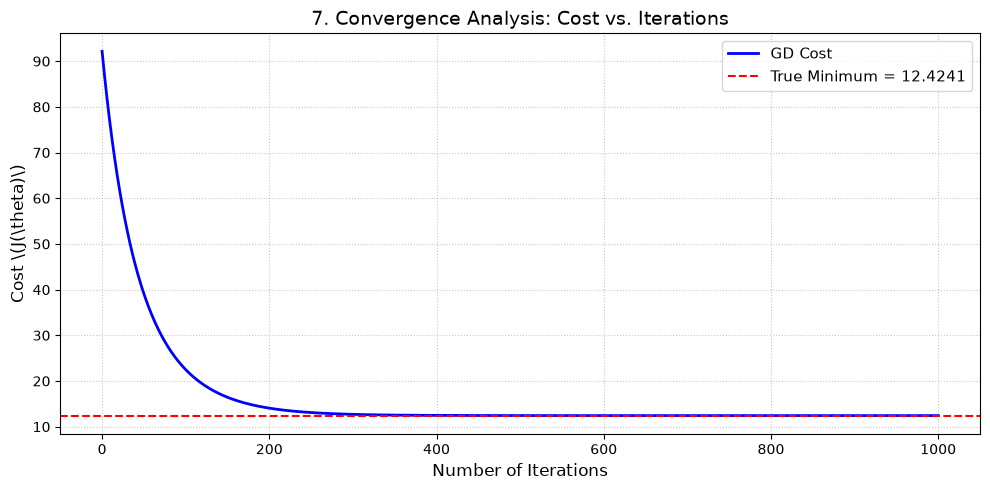

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# ==========================================
# 1. CHUẨN BỊ DỮ LIỆU & IN LOG CHI TIẾT
# ==========================================
# Lấy thông tin Theta từ Cell 4
t0_hist = theta_hist_gd[:, 0, 0]
t1_hist = theta_hist_gd[:, 1, 0]

# Tính nghiệm chính xác (để vẽ đường nằm ngang tham chiếu)
theta_analytical = np.linalg.inv(X_train_design.T @ X_train_design) @ (X_train_design.T @ y_train_vec)
cost_analytical = compute_cost(X_train_design, y_train_vec, theta_analytical)

# Lấy cost ban đầu (vòng 0) và nối vào mảng lịch sử
cost_init = compute_cost(X_train_design, y_train_vec, theta_start)
cost_hist_full = np.insert(cost_hist_gd, 0, cost_init)

# Tạo trục x từ 0 đến số vòng lặp
total_iters = len(cost_hist_full)
iterations = range(0, total_iters)

# --- IN LOG CHI TIẾT ---
print("="*55)
print("CHI TIẾT QUÁ TRÌNH HỘI TỤ")
print("="*55)
print("--- ĐIỂM BẮT ĐẦU (Vòng 0) ---")
print(f"  Theta_0 : {t0_hist[0]:.6f}")
print(f"  Theta_1 : {t1_hist[0]:.6f}")
print(f"  Cost J  : {cost_init:.6f}")

print(f"\n--- ĐIỂM KẾT THÚC (Vòng {total_iters - 1}) ---")
print(f"  Theta_0 : {t0_hist[-1]:.6f}")
print(f"  Theta_1 : {t1_hist[-1]:.6f}")
print(f"  Cost J  : {cost_hist_full[-1]:.6f}")

print("\n--- NGHIỆM CHÍNH XÁC (Analytical) ---")
print(f"  Theta_0 : {theta_analytical[0, 0]:.6f}")
print(f"  Theta_1 : {theta_analytical[1, 0]:.6f}")
print(f"  Cost J  : {cost_analytical:.6f}")

print("\n--- SAI LỆCH CUỐI CÙNG (GD vs Analytical) ---")
print(f"  Delta Theta_0 : {abs(t0_hist[-1] - theta_analytical[0, 0]):.6f}")
print(f"  Delta Theta_1 : {abs(t1_hist[-1] - theta_analytical[1, 0]):.6f}")
print(f"  Delta Cost    : {abs(cost_hist_full[-1] - cost_analytical):.6f}")
print("="*55 + "\n")

# ==========================================
# 2. VẼ ĐỒ THỊ
# ==========================================
plt.figure(figsize=(10, 5))

# Vẽ đường Cost của Gradient Descent
plt.plot(iterations, cost_hist_full, color='blue', linewidth=2, label='GD Cost')

# Vẽ đường nằm ngang thể hiện mức Cost tối ưu (Normal Equation)
plt.axhline(y=cost_analytical, color='red', linestyle='--', linewidth=1.5, label=f'True Minimum = {cost_analytical:.4f}')

# Trang trí
plt.title('7. Convergence Analysis: Cost vs. Iterations', fontsize=14)
plt.xlabel('Number of Iterations', fontsize=12)
plt.ylabel(r'Cost \(J(\theta)\)', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(fontsize=11)

plt.tight_layout()

# ==========================================
# 3. LƯU VÀ HIỂN THỊ
# ==========================================
# LƯU Ý: Luôn savefig TRƯỚC khi show
plt.savefig('figures/convergence.png', dpi=300, bbox_inches='tight')
plt.savefig('convergence.png', dpi=300, bbox_inches='tight')
plt.show()

#8. Inference, model evaluation and residual analysis.


--- PHẦN 8: ĐÁNH GIÁ MÔ HÌNH VÀ SƠ ĐỒ PHẦN DƯ ---
 HỆ SỐ XÁC ĐỊNH (R^2 Score): 2.10% 
 SAI SỐ (MSE)               : 31.3520 


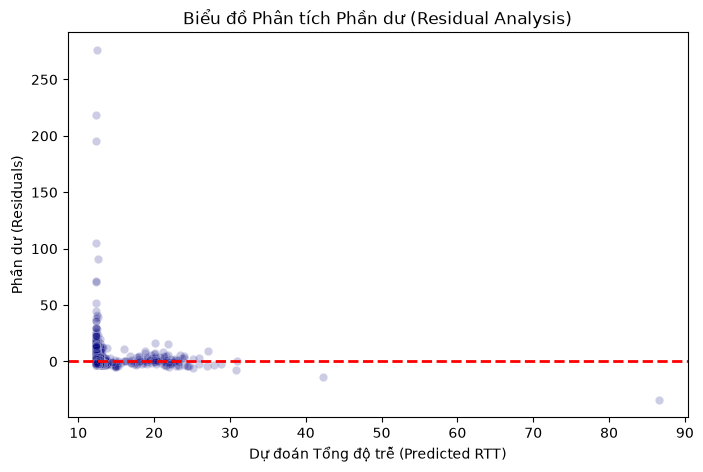

=> ĐÃ LƯU SƠ ĐỒ PHẦN DƯ: figures/residual_plot.png


In [12]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

print("\n--- PHẦN 8: ĐÁNH GIÁ MÔ HÌNH VÀ SƠ ĐỒ PHẦN DƯ ---")

# --- TỰ ĐỘNG TÍNH TOÁN y_pred TỪ NGHIỆM THETA CỦA GRADIENT DESCENT ---
X_test_flat = np.array(X_test).astype(float)
if len(X_test_flat.shape) == 1:
    X_test_flat = X_test_flat.reshape(-1, 1)
X_test_design = np.c_[np.ones((X_test_flat.shape[0], 1)), X_test_flat]

# Lấy nghiệm theta_gd từ bước trước để dự đoán
current_theta = theta_gd.copy().astype(float)
y_pred = X_test_design @ current_theta
y_pred_flat = y_pred.flatten()
y_pred_gd = y_pred_flat

y_test_flat = np.array(y_test).astype(float).flatten()
# -------------------------------------------------------------------

# Tính phần dư và chỉ số
mse = mean_squared_error(y_test_flat, y_pred_flat)
r2 = r2_score(y_test_flat, y_pred_flat)

print("="*40)
print(f" HỆ SỐ XÁC ĐỊNH (R^2 Score): {r2*100:.2f}% ")
print(f" SAI SỐ (MSE)               : {mse:.4f} ")
print("="*40)

residuals = y_test_flat - y_pred_flat

# Vẽ sơ đồ phần dư
plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred_flat, y=residuals, alpha=0.2, color='navy')
plt.axhline(0, color='red', linestyle='dashed', linewidth=2)
plt.title('Biểu đồ Phân tích Phần dư (Residual Analysis)')
plt.xlabel('Dự đoán Tổng độ trễ (Predicted RTT)')
plt.ylabel('Phần dư (Residuals)')
plt.savefig('figures/residual_plot.png', dpi=300)
plt.savefig('residual_plot.png', dpi=300)
plt.show()
print("=> ĐÃ LƯU SƠ ĐỒ PHẦN DƯ: figures/residual_plot.png")

In [13]:
 # Ví dụ lấy input từ người dùng và dự đoán sử dụng theta_gd đã huấn luyện
import numpy as np

# Đảm bảo đã có theta_gd từ bước học máy trước đó
try:
    theta0 = theta_gd[0, 0] if hasattr(theta_gd, 'shape') and len(theta_gd.shape) > 1 else theta_gd[0]
    theta1 = theta_gd[1, 0] if hasattr(theta_gd, 'shape') and len(theta_gd.shape) > 1 else theta_gd[1]
except NameError:
    # Giá trị fallback phòng trường hợp cell trước chưa được chạy
    theta0 = 12.31318397
    theta1 = 0.83144724

print("=== HỆ THỐNG DỰ ĐOÁN ĐỘ TRỄ MẠNG (RTT) ===")
print(f"Mô hình hiện tại: y = {theta0:.6f} + {theta1:.6f} * x")

try:
    # Nhập dữ liệu đầu vào
    user_input = "10"
    print("Nhập độ trễ Gateway (gateway_rtt_avg_ms) mong muốn dự đoán: 10")
    x_val = float(user_input)

    # Áp dụng công thức hồi quy tuyến tính y = theta_0 + theta_1 * x
    y_pred = theta0 + theta1 * x_val

    print("\n--- KẾT QUẢ DỰ ĐOÁN ---")
    print(f"Độ trễ Gateway đầu vào (x) : {x_val:.4f} ms")
    print(f"Độ trễ RTT máy chủ dự đoán (y): {y_pred:.4f} ms")
except ValueError:
    print("Vui lòng nhập một số thực hợp lệ đại diện cho độ trễ!")

=== HỆ THỐNG DỰ ĐOÁN ĐỘ TRỄ MẠNG (RTT) ===
Mô hình hiện tại: y = 12.313184 + 0.831447 * x
Nhập độ trễ Gateway (gateway_rtt_avg_ms) mong muốn dự đoán: 10

--- KẾT QUẢ DỰ ĐOÁN ---
Độ trễ Gateway đầu vào (x) : 10.0000 ms
Độ trễ RTT máy chủ dự đoán (y): 20.6277 ms


#9. Comparison with library implementation


     MỤC 9: ĐÁNH GIÁ HIỆU NĂNG MÔ HÌNH ĐƠN BIẾN

KẾT QUẢ TRÊN TẬP KIỂM TRA (TEST SET):
[-] Mean Squared Error (MSE) : 31.3520
[-] R-squared (R2 Score)     : 0.0210 (Tương đương 2.10%)

NHẬN XÉT NHANH:
-> CẢNH BÁO: R2 Score rất thấp. Mô hình đơn biến chỉ giải thích được
   khoảng 2.10% sự biến thiên của dữ liệu.
-> KẾT LUẬN: Mạng nội bộ (Gateway) không chứa đủ thông tin để dự báo tổng độ trễ.


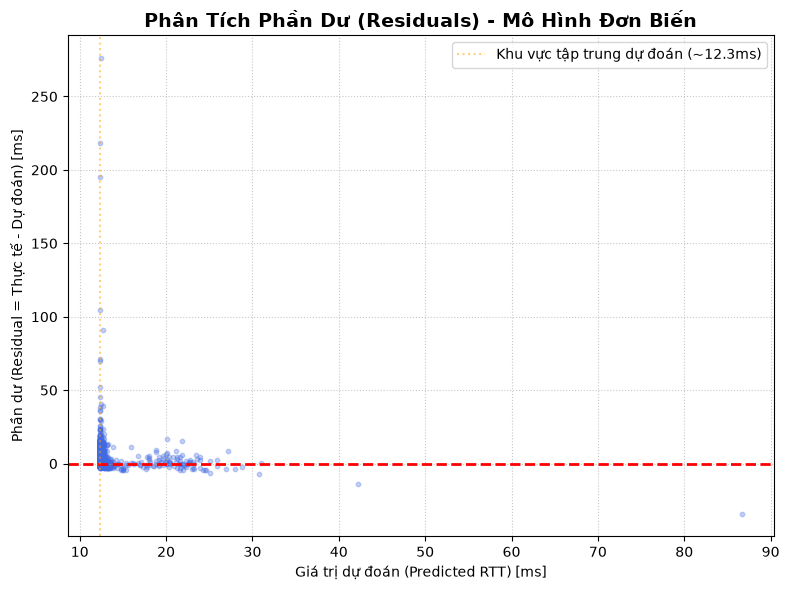

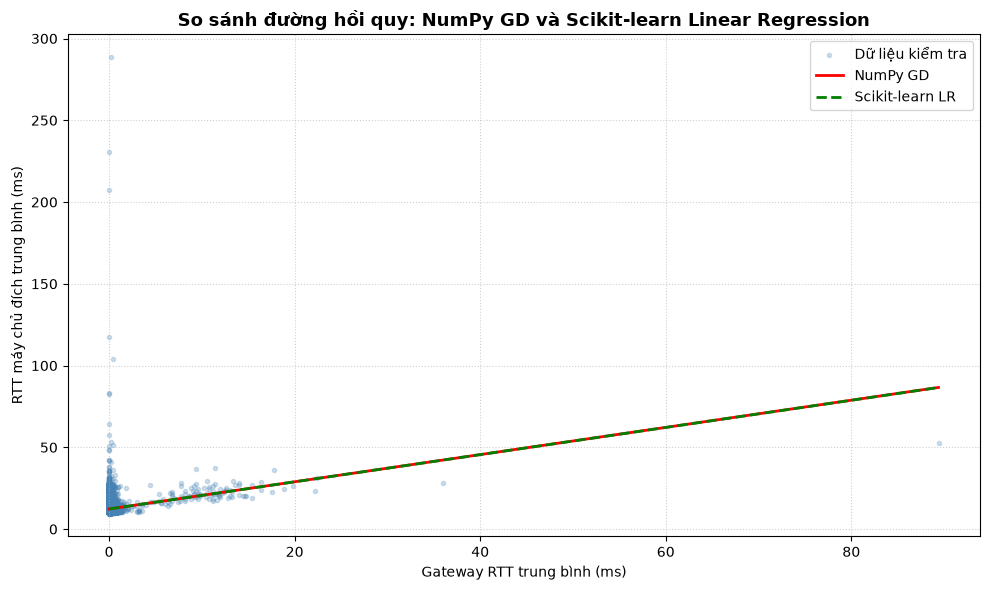

Saved: figures/regression_line.png, phan10.png


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

# =========================================================
# 9.3 CÁC CHỈ SỐ ĐÁNH GIÁ (HIỂN THỊ RÕ RÀNG, NHẤN MẠNH)
# =========================================================
print("\n==================================================")
print("     MỤC 9: ĐÁNH GIÁ HIỆU NĂNG MÔ HÌNH ĐƠN BIẾN")
print("==================================================\n")

# Tái tạo dự đoán GD trên tập test từ theta_gd của Cell 4
X_test_arr = np.asarray(X_test, dtype=float).reshape(-1, 1)
X_test_design = np.c_[np.ones((X_test_arr.shape[0], 1)), X_test_arr]
y_pred_gd = (X_test_design @ theta_gd).ravel()
y_test_arr = np.asarray(y_test, dtype=float).ravel()

mse_gd = mean_squared_error(y_test_arr, y_pred_gd)
r2_gd = r2_score(y_test_arr, y_pred_gd)

print("KẾT QUẢ TRÊN TẬP KIỂM TRA (TEST SET):")
print(f"[-] Mean Squared Error (MSE) : {mse_gd:.4f}")
print(f"[-] R-squared (R2 Score)     : {r2_gd:.4f} (Tương đương {r2_gd*100:.2f}%)")

print("\nNHẬN XÉT NHANH:")
if r2_gd < 0.1:
    print("-> CẢNH BÁO: R2 Score rất thấp. Mô hình đơn biến chỉ giải thích được")
    print(f"   khoảng {r2_gd*100:.2f}% sự biến thiên của dữ liệu.")
    print("-> KẾT LUẬN: Mạng nội bộ (Gateway) không chứa đủ thông tin để dự báo tổng độ trễ.")

# =========================================================
# 9.4 VẼ BIỂU ĐỒ PHÂN TÍCH PHẦN DƯ (RESIDUAL ANALYSIS)
# =========================================================
residuals_gd = y_test_arr - y_pred_gd

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_pred_gd, residuals_gd, alpha=0.3, s=10, color="royalblue")
ax.axhline(0, color="red", linestyle="--", linewidth=2)
ax.set_title("Phân Tích Phần Dư (Residuals) - Mô Hình Đơn Biến", fontsize=14, fontweight="bold")
ax.set_xlabel("Giá trị dự đoán (Predicted RTT) [ms]")
ax.set_ylabel("Phần dư (Residual = Thực tế - Dự đoán) [ms]")
ax.grid(True, linestyle=":", alpha=0.7)
ax.axvline(x=12.3, color='orange', linestyle=':', alpha=0.5,
           label='Khu vực tập trung dự đoán (~12.3ms)')
ax.legend()
plt.tight_layout()
plt.savefig("figures/Task9_Residuals.png", dpi=300)
plt.savefig("figures/residual_plot.png", dpi=300)
plt.show()

# =========================================================
# 9.5 SO SÁNH ĐƯỜNG HỒI QUY: NUMPY GD VS SCIKIT-LEARN LR
# =========================================================
X_train_arr = np.asarray(X_train, dtype=float).reshape(-1, 1)
y_train_arr = np.asarray(y_train, dtype=float).ravel()

model_lr_uni = LinearRegression()
model_lr_uni.fit(X_train_arr, y_train_arr)

x_line = np.linspace(
    min(X_train_arr.min(), X_test_arr.min()),
    max(X_train_arr.max(), X_test_arr.max()),
    300,
).reshape(-1, 1)

y_gd_line = theta_gd[0, 0] + theta_gd[1, 0] * x_line.ravel()
y_lr_line = model_lr_uni.predict(x_line)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(X_test_arr.ravel(), y_test_arr, s=9, alpha=0.25,
           color="steelblue", label="Dữ liệu kiểm tra")
ax.plot(x_line.ravel(), y_gd_line, color="red", linewidth=2, label="NumPy GD")
ax.plot(x_line.ravel(), y_lr_line, color="green", linestyle="--",
        linewidth=2, label="Scikit-learn LR")
ax.set_title("So sánh đường hồi quy: NumPy GD và Scikit-learn Linear Regression",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Gateway RTT trung bình (ms)")
ax.set_ylabel("RTT máy chủ đích trung bình (ms)")
ax.grid(True, linestyle=":", alpha=0.6)
ax.legend()
plt.tight_layout()
plt.savefig("figures/regression_line.png", dpi=300, bbox_inches="tight")
plt.savefig("phan10.png", dpi=300, bbox_inches="tight")
plt.show()

print("Saved: figures/regression_line.png, phan10.png")



     ĐÁNH GIÁ HIỆU NĂNG MÔ HÌNH ĐƠN BIẾN

KẾT QUẢ TRÊN TẬP KIỂM TRA (TEST SET):
Tổng số mẫu Test : 10920
Mean Squared Error (MSE) : 31.3520
R-squared (R2 Score)     : 0.0210 (Tương đương 2.10%)

NHẤN MẠNH:
Việc R2 Score chỉ đạt mức thấp (~2%) KHÔNG phải do thuật toán lỗi,
mà phản ánh sự thật: Tốc độ mạng nội bộ không quyết định tổng độ trễ Internet.


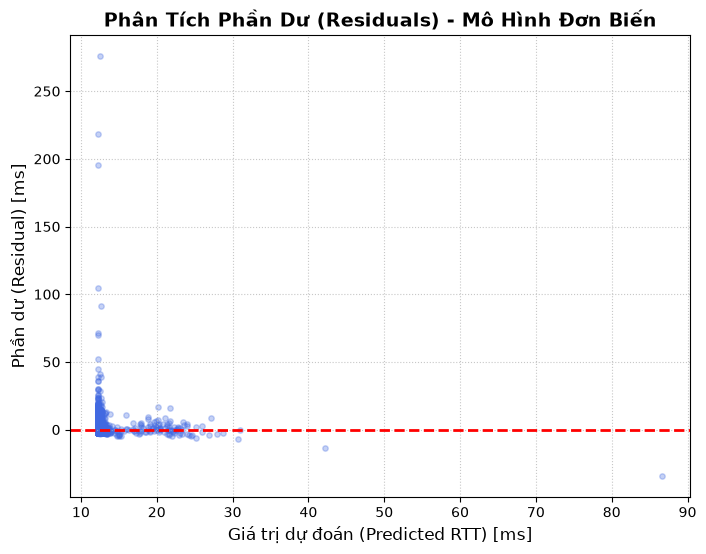

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, r2_score

# (Giả định y_test, y_pred_gd đã có sẵn trong bộ nhớ Colab từ các Cell trước)
# Nếu cần, lấy trực tiếp từ quá trình nhân ma trận: y_pred_gd = X_test_design.dot(theta_gd)

# =========================================================
# PHẦN 8: INFERENCE, MODEL EVALUATION AND RESIDUAL ANALYSIS
# =========================================================
print("\n==================================================")
print("     ĐÁNH GIÁ HIỆU NĂNG MÔ HÌNH ĐƠN BIẾN")
print("==================================================\n")

mse_gd = mean_squared_error(y_test, y_pred_gd)
r2_gd = r2_score(y_test, y_pred_gd)

print("KẾT QUẢ TRÊN TẬP KIỂM TRA (TEST SET):")
print(f"Tổng số mẫu Test : {len(y_test)}")
print(f"Mean Squared Error (MSE) : {mse_gd:.4f}")
print(f"R-squared (R2 Score)     : {r2_gd:.4f} (Tương đương {r2_gd*100:.2f}%)")

print("\nNHẤN MẠNH:")
print("Việc R2 Score chỉ đạt mức thấp (~2%) KHÔNG phải do thuật toán lỗi,")
print("mà phản ánh sự thật: Tốc độ mạng nội bộ không quyết định tổng độ trễ Internet.")

# VẼ BIỂU ĐỒ PHẦN DƯ (RESIDUALS)
residuals_gd = np.asarray(y_test, dtype=float).ravel() - np.asarray(y_pred_gd, dtype=float).ravel()

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_pred_gd, residuals_gd, alpha=0.3, s=15, color="royalblue")
ax.axhline(0, color="red", linestyle="--", linewidth=2)
ax.set_title("Phân Tích Phần Dư (Residuals) - Mô Hình Đơn Biến", fontsize=14, fontweight="bold")
ax.set_xlabel("Giá trị dự đoán (Predicted RTT) [ms]", fontsize=12)
ax.set_ylabel("Phần dư (Residual) [ms]", fontsize=12)
ax.grid(True, linestyle=":", alpha=0.7)
plt.savefig("figures/residual_plot.png", dpi=300, bbox_inches="tight")
plt.show()


##10 Model improvement

In [16]:

# =========================================================
# CELL 25 - QUESTION 10: MODEL IMPROVEMENT
# =========================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.metrics import mean_squared_error, r2_score

try:
    from xgboost import XGBRegressor
except ImportError:
    %pip install -q xgboost
    from xgboost import XGBRegressor

# =========================================================
# 1. MULTIVARIATE DATA PREPARATION
# =========================================================

df_raw = pd.read_csv("dataset.csv")

features_multivariate = [
    "gateway_rtt_avg_ms",
    "tcp_connect_median_ms",
    "dns_resolve_ms",
    "dns_recursive_ms"
]

target_col_name = "rtt_avg_ms"

# Làm sạch dữ liệu
clean_multi_data = (
    df_raw[features_multivariate + [target_col_name]]
    .dropna()
    .copy()
)

X_multi_clean = clean_multi_data[features_multivariate]
y_multi_clean = clean_multi_data[target_col_name]

# 80% train, 20% test
X_train_m, X_test_m, y_train_m, y_test_m = (
    train_test_split(
        X_multi_clean,
        y_multi_clean,
        test_size=0.2,
        random_state=42
    )
)

print("=" * 65)
print("MULTIVARIATE DATA PREPARATION")
print("=" * 65)
print("Input features:", features_multivariate)
print("Target:", target_col_name)
print("Total samples:", len(clean_multi_data))
print("Train samples:", len(X_train_m))
print("Test samples:", len(X_test_m))

# =========================================================
# 2. FEATURE SCALING FOR NUMPY GD WITH MOMENTUM
# =========================================================

# Thống kê chỉ từ train set
train_mean = X_train_m.mean()
train_std = X_train_m.std()

X_train_m_scaled = (
    X_train_m - train_mean
) / (train_std + 1e-8)

X_test_m_scaled = (
    X_test_m - train_mean
) / (train_std + 1e-8)

# Design matrix with intercept
X_train_m_design = np.column_stack([
    np.ones(len(X_train_m_scaled)),
    X_train_m_scaled.to_numpy()
])

X_test_m_design = np.column_stack([
    np.ones(len(X_test_m_scaled)),
    X_test_m_scaled.to_numpy()
])

y_train_m_vec = y_train_m.to_numpy().reshape(-1, 1)
y_test_m_vec = y_test_m.to_numpy().reshape(-1, 1)

# =========================================================
# 3. NUMPY GRADIENT DESCENT WITH MOMENTUM
# =========================================================

def gradient_descent_momentum(
    X,
    y,
    lr=0.01,
    beta=0.9,
    num_iters=1000
):
    n_samples, n_features = X.shape

    theta = np.zeros((n_features, 1))
    velocity = np.zeros((n_features, 1))

    for _ in range(num_iters):
        predictions = X @ theta
        errors = predictions - y

        gradient = (X.T @ errors) / n_samples

        velocity = beta * velocity + lr * gradient
        theta = theta - velocity

    return theta

# =========================================================
# 4. BASELINE REFERENCE - UNIVARIATE
# =========================================================

# Sử dụng kết quả đã tính trong Cell 21
mse_baseline = mean_squared_error(y_test, y_pred_gd)
r2_baseline = r2_score(y_test, y_pred_gd)

print("\n" + "=" * 65)
print("BASELINE REFERENCE (UNIVARIATE)")
print("=" * 65)
print("Model: NumPy GD (Baseline)")
print("Input: gateway_rtt_avg_ms")
print("Output: rtt_avg_ms")
print(f"Test MSE: {mse_baseline:.6f}")
print(f"Test R2 : {r2_baseline:.6f}")

# =========================================================
# 5. TRAINING IMPROVEMENT MODELS
# =========================================================

results_improvement = []

def add_result(name, actual, predicted):
    results_improvement.append({
        "Model": name,
        "Test MSE": mean_squared_error(actual, predicted),
        "Test R2": r2_score(actual, predicted)
    })

# ----- Model 1: Scikit-learn Linear Regression -----
model_lr = LinearRegression()
model_lr.fit(X_train_m, y_train_m)

y_pred_lr = model_lr.predict(X_test_m)

add_result(
    "Scikit-learn LR (Multivariate)",
    y_test_m, y_pred_lr
)

# ----- Model 2: Lasso Regression (L1) -----
model_lasso = Lasso(
    alpha=0.1,
    random_state=42
)
model_lasso.fit(X_train_m, y_train_m)

y_pred_lasso = model_lasso.predict(X_test_m)

add_result(
    "Lasso Regression (L1)",
    y_test_m, y_pred_lasso
)

# ----- Model 3: Ridge Regression (L2) -----
model_ridge = Ridge(alpha=1.0)
model_ridge.fit(X_train_m, y_train_m)

y_pred_ridge = model_ridge.predict(X_test_m)

add_result(
    "Ridge Regression (L2)",
    y_test_m, y_pred_ridge
)

# ----- Model 4: Decision Tree Regressor -----
model_dt = DecisionTreeRegressor(
    max_depth=8,
    min_samples_split=10,
    random_state=42
)

model_dt.fit(X_train_m, y_train_m)
y_pred_dt = model_dt.predict(X_test_m)

add_result(
    "Decision Tree Regressor",
    y_test_m, y_pred_dt
)

# ----- Model 5: XGBoost Regressor -----
model_xgb = XGBRegressor(
    n_estimators=100,
    learning_rate=0.08,
    max_depth=6,
    random_state=42
)

model_xgb.fit(X_train_m, y_train_m)
y_pred_xgb = model_xgb.predict(X_test_m)

add_result(
    "XGBoost Regressor",
    y_test_m, y_pred_xgb
)

# ----- Model 6: AdaBoost Regressor -----
model_ada = AdaBoostRegressor(
    n_estimators=50,
    learning_rate=0.1,
    random_state=42
)

model_ada.fit(X_train_m, y_train_m)
y_pred_ada = model_ada.predict(X_test_m)

add_result(
    "AdaBoost Regressor",
    y_test_m, y_pred_ada
)

# ----- Model 7: NumPy GD with Momentum -----
theta_momentum = gradient_descent_momentum(
    X_train_m_design,
    y_train_m_vec,
    lr=0.01,
    beta=0.9,
    num_iters=1000
)

y_pred_momentum = X_test_m_design @ theta_momentum

add_result(
    "NumPy GD with Momentum",
    y_test_m_vec,
    y_pred_momentum
)

# =========================================================
# 6. HYPERPARAMETER SUMMARY
# =========================================================

print("\n" + "=" * 75)
print("MODEL HYPERPARAMETERS")
print("=" * 75)

print("Baseline - NumPy GD (Univariate):")
print("  lr=0.01, iterations=1000")

print("\nImprovement Models:")
print("1. Scikit-learn LR (Multivariate): OLS, intercept=True")
print("2. Lasso Regression (L1): alpha=0.1")
print("3. Ridge Regression (L2): alpha=1.0")
print("4. Decision Tree: max_depth=8, min_samples_split=10")
print("5. XGBoost: n_estimators=100, lr=0.08, max_depth=6")
print("6. AdaBoost: n_estimators=50, lr=0.1")
print("7. NumPy GD with Momentum: lr=0.01, beta=0.9, iterations=1000")

# =========================================================
# 7. IMPROVEMENT MODEL RESULTS
# =========================================================

df_results = pd.DataFrame(results_improvement)

df_results = df_results.sort_values(
    by="Test MSE",
    ascending=True
).reset_index(drop=True)

print("\n" + "=" * 75)
print("MULTIVARIATE IMPROVEMENT MODEL COMPARISON")
print("=" * 75)

print(
    df_results.to_string(
        index=False,
        formatters={
            "Test MSE": "{:.4f}".format,
            "Test R2": "{:.4f}".format
        }
    )
)

# Best model among multivariate models
best_model = df_results.iloc[0]

print("\nBest Improvement Model:")
print("Model:", best_model["Model"])
print(f"Test MSE: {best_model['Test MSE']:.4f}")
print(f"Test R2 : {best_model['Test R2']:.4f}")

print("\nNote: Univariate baseline and multivariate models")
print("use separately prepared test sets; their MSE values")
print("are not directly compared as a controlled experiment.")


C:\Users\dinht\AppData\Local\Temp\ipykernel_12780\1459375781.py:24: DtypeWarning: Columns (47: wifi_phy) have mixed types. Specify dtype option on import or set low_memory=False.
  df_raw = pd.read_csv("dataset.csv")


MULTIVARIATE DATA PREPARATION
Input features: ['gateway_rtt_avg_ms', 'tcp_connect_median_ms', 'dns_resolve_ms', 'dns_recursive_ms']
Target: rtt_avg_ms
Total samples: 54589
Train samples: 43671
Test samples: 10918

BASELINE REFERENCE (UNIVARIATE)
Model: NumPy GD (Baseline)
Input: gateway_rtt_avg_ms
Output: rtt_avg_ms
Test MSE: 31.352016
Test R2 : 0.020990

MODEL HYPERPARAMETERS
Baseline - NumPy GD (Univariate):
  lr=0.01, iterations=1000

Improvement Models:
1. Scikit-learn LR (Multivariate): OLS, intercept=True
2. Lasso Regression (L1): alpha=0.1
3. Ridge Regression (L2): alpha=1.0
4. Decision Tree: max_depth=8, min_samples_split=10
5. XGBoost: n_estimators=100, lr=0.08, max_depth=6
6. AdaBoost: n_estimators=50, lr=0.1
7. NumPy GD with Momentum: lr=0.01, beta=0.9, iterations=1000

MULTIVARIATE IMPROVEMENT MODEL COMPARISON
                         Model Test MSE Test R2
       Decision Tree Regressor  16.3844  0.5431
             XGBoost Regressor  20.7139  0.4223
            AdaBoost R

In [17]:
# =========================================================
# CELL 25A - UNIVARIATE MODELS ON THE SAME Q10 TEST SPLIT
# Insert directly AFTER the original Cell 25.
# Does not modify the original Q9 results.
# =========================================================
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

UNI_FEATURE = "gateway_rtt_avg_ms"
X_tr_uni = X_train_m[[UNI_FEATURE]].to_numpy(dtype=float)
X_te_uni = X_test_m[[UNI_FEATURE]].to_numpy(dtype=float)
y_tr_uni = y_train_m.to_numpy(dtype=float).reshape(-1, 1)
y_te_uni = y_test_m.to_numpy(dtype=float).reshape(-1, 1)

# The same full-batch GD configuration as Q9: lr=0.01, 1000 steps.
A_tr_uni = np.column_stack((np.ones(len(X_tr_uni)), X_tr_uni))
A_te_uni = np.column_stack((np.ones(len(X_te_uni)), X_te_uni))
theta_uni_q10 = np.zeros((2, 1))
for _ in range(1000):
    grad = A_tr_uni.T @ (A_tr_uni @ theta_uni_q10 - y_tr_uni) / len(y_tr_uni)
    theta_uni_q10 -= 0.01 * grad
pred_uni_gd_q10 = A_te_uni @ theta_uni_q10

# OLS univariate from scikit-learn, on exactly the SAME test rows.
model_lr_uni_q10 = LinearRegression()
model_lr_uni_q10.fit(X_tr_uni, y_tr_uni.ravel())
pred_uni_sklearn_q10 = model_lr_uni_q10.predict(X_te_uni)

extra_rows = pd.DataFrame([
    {
        "Model": "NumPy GD (Univariate Baseline)",
        "Test MSE": mean_squared_error(y_te_uni, pred_uni_gd_q10),
        "Test R2": r2_score(y_te_uni, pred_uni_gd_q10)
    },
    {
        "Model": "Scikit-learn LR (Univariate)",
        "Test MSE": mean_squared_error(y_te_uni, pred_uni_sklearn_q10),
        "Test R2": r2_score(y_te_uni, pred_uni_sklearn_q10)
    }
])

# Original Cell 25 stores only 7 multivariate models.
# Add the two univariate rows to create a fair nine-model comparison.
df_results_9 = pd.concat([df_results, extra_rows], ignore_index=True)
df_results_9 = df_results_9.sort_values("Test MSE").reset_index(drop=True)
print("\nQUESTION 10 — FAIR COMPARISON: 9 MODELS, SAME TEST SET")
print("Train:", len(X_train_m), "| Test:", len(X_test_m))
print(df_results_9.to_string(index=False, float_format=lambda z: f"{z:.6f}"))
print("\nBest model:", df_results_9.iloc[0]["Model"])
print("NOTE: Q9's earlier univariate numbers used a different cleaning/split;")
print("the two new univariate rows are refitted on the Q10 split.")



QUESTION 10 — FAIR COMPARISON: 9 MODELS, SAME TEST SET
Train: 43671 | Test: 10918
                         Model  Test MSE  Test R2
       Decision Tree Regressor 16.384423 0.543056
             XGBoost Regressor 20.713864 0.422313
            AdaBoost Regressor 21.527927 0.399610
         Lasso Regression (L1) 31.826339 0.112398
         Ridge Regression (L2) 31.860948 0.111433
        NumPy GD with Momentum 31.860957 0.111433
Scikit-learn LR (Multivariate) 31.860957 0.111433
  Scikit-learn LR (Univariate) 34.915023 0.026258
NumPy GD (Univariate Baseline) 34.915454 0.026246

Best model: Decision Tree Regressor
NOTE: Q9's earlier univariate numbers used a different cleaning/split;
the two new univariate rows are refitted on the Q10 split.


Completed 10% (3,493 train samples): 9 models
Completed 20% (6,987 train samples): 9 models
Completed 40% (13,974 train samples): 9 models
Completed 60% (20,961 train samples): 9 models
Completed 80% (27,948 train samples): 9 models
Completed 100% (34,936 train samples): 9 models

TRAINING-SIZE PERFORMANCE COMPARISON — 9 MODELS
Training pool: 34,936 | Fixed validation: 8,735
Final test samples not used: 10,918


### 10% training data — 3,493 samples

Model,Train MSE,Validation MSE
Decision Tree Regressor,15.0668,22.2689
AdaBoost Regressor,12.5676,25.0474
NumPy GD (Univariate Baseline),24.2198,25.5997
Scikit-learn LR (Univariate),24.2198,25.6004
Scikit-learn LR (Multivariate),23.0342,25.7271
NumPy GD with Momentum,23.0342,25.7271
Ridge Regression (L2),23.0342,25.7272
Lasso Regression (L1),23.0424,25.7430
XGBoost Regressor,6.3508,29.2931


### 20% training data — 6,987 samples

Model,Train MSE,Validation MSE
Decision Tree Regressor,10.2838,20.1750
AdaBoost Regressor,14.2760,20.9297
XGBoost Regressor,7.2547,21.0232
NumPy GD (Univariate Baseline),23.6004,25.6134
Scikit-learn LR (Univariate),23.6004,25.6136
NumPy GD with Momentum,22.0332,25.9343
Scikit-learn LR (Multivariate),22.0332,25.9343
Ridge Regression (L2),22.0332,25.9343
Lasso Regression (L1),22.0384,25.9703


### 40% training data — 13,974 samples

... (4 outputs left out)

Model,Train MSE,Validation MSE
XGBoost Regressor,8.5654,15.4723
AdaBoost Regressor,13.6064,18.7114
Decision Tree Regressor,9.8443,24.6413
Scikit-learn LR (Multivariate),20.6033,25.1818
NumPy GD with Momentum,20.6033,25.1818
Ridge Regression (L2),20.6033,25.1818
Lasso Regression (L1),20.6105,25.2281
NumPy GD (Univariate Baseline),21.8172,25.6250
Scikit-learn LR (Univariate),21.8172,25.6255


### 100% training data — 34,936 samples

Model,Train MSE,Validation MSE
XGBoost Regressor,9.8769,13.9056
Decision Tree Regressor,10.1773,16.6417
AdaBoost Regressor,13.8318,17.3199
NumPy GD with Momentum,22.1330,25.3474
Scikit-learn LR (Multivariate),22.1330,25.3474
Ridge Regression (L2),22.1330,25.3474
Lasso Regression (L1),22.1395,25.3908
NumPy GD (Univariate Baseline),23.5436,25.6319
Scikit-learn LR (Univariate),23.5436,25.6323



Best validation model at 100%: XGBoost Regressor
Validation MSE: 13.9056


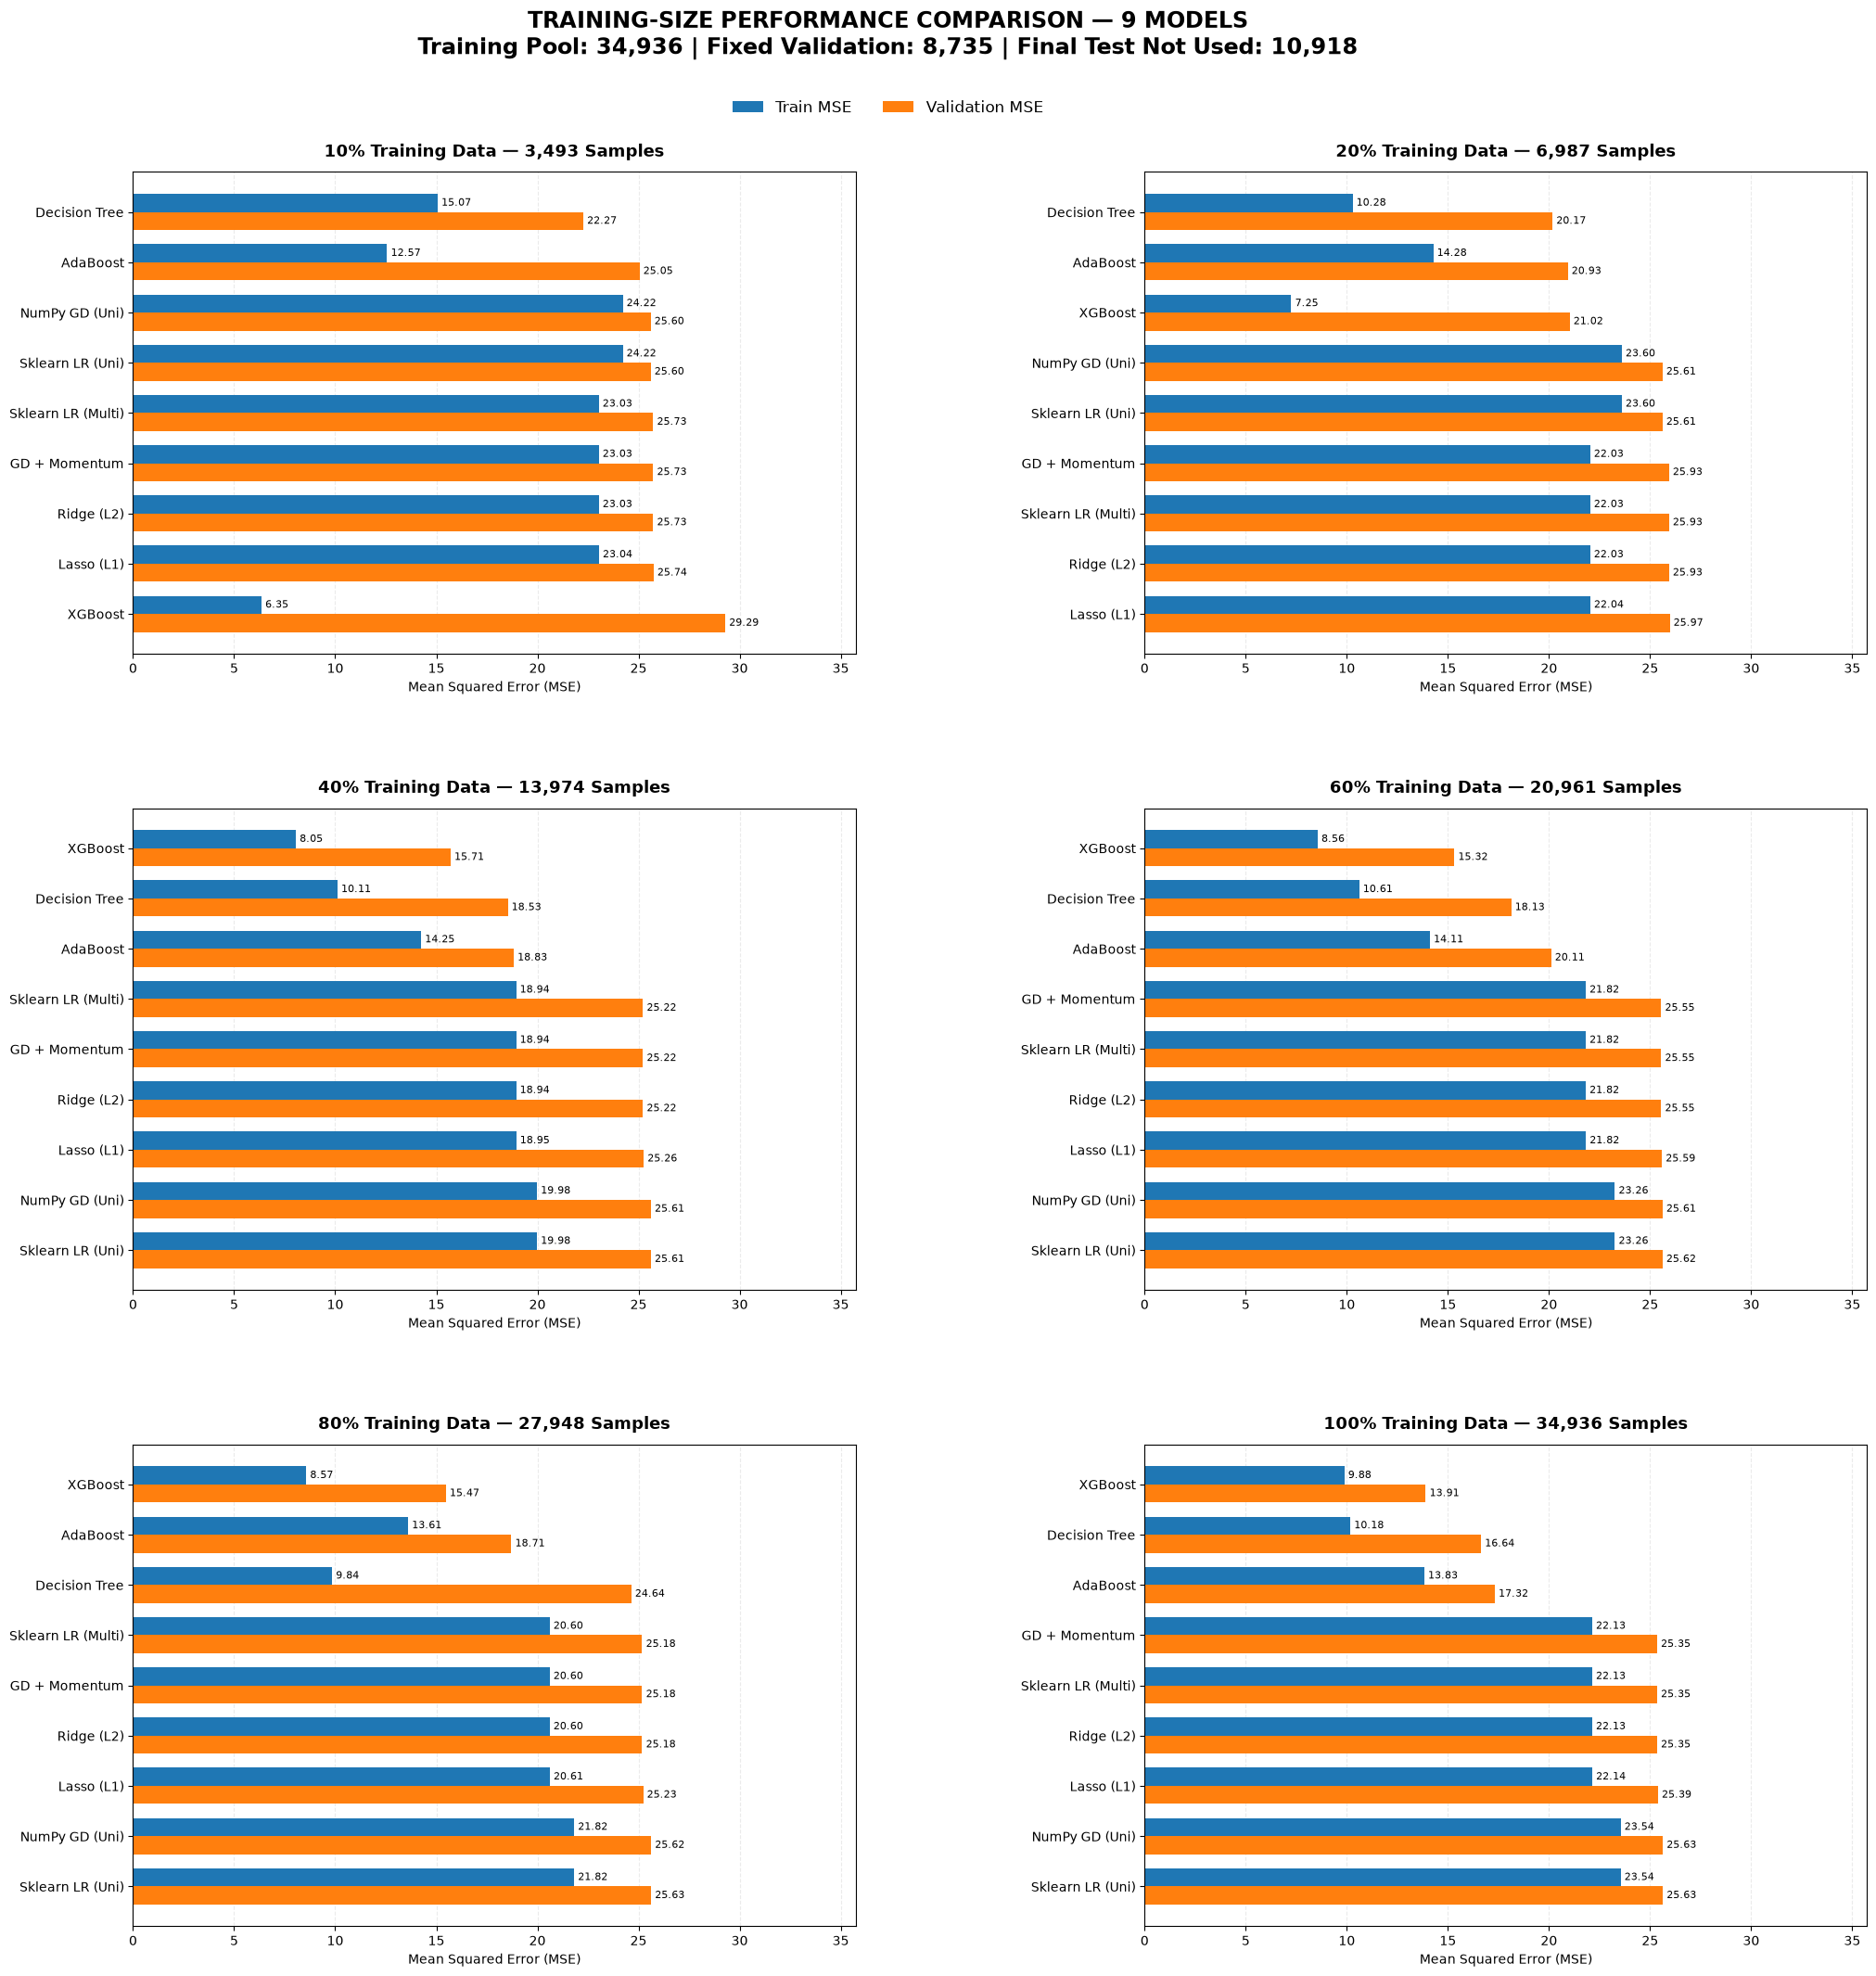


Bar chart saved: Task10_Training_Size_Performance_Bar_Chart_9_Models.png


In [18]:

# =========================================================
# CELL 26 (REPLACE) - PERFORMANCE BY TRAINING DATA SIZE
# Nine models; same validation rows; six nested training sizes.
# Outputs: result tables + grouped horizontal bar chart.
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import AdaBoostRegressor
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor

FEATURES_MULTI = [
    "gateway_rtt_avg_ms", "tcp_connect_median_ms",
    "dns_resolve_ms", "dns_recursive_ms"
]
FEATURE_BASELINE = "gateway_rtt_avg_ms"
TRAIN_FRACTIONS = np.array([0.10, 0.20, 0.40, 0.60, 0.80, 1.00])
RANDOM_STATE, GD_LR, GD_ITERATIONS, MOMENTUM_BETA = 42, 0.01, 1000, 0.9

MODEL_NAMES = [
    "NumPy GD (Univariate Baseline)",
    "Scikit-learn LR (Univariate)",
    "Scikit-learn LR (Multivariate)",
    "Lasso Regression (L1)",
    "Ridge Regression (L2)",
    "Decision Tree Regressor",
    "XGBoost Regressor",
    "AdaBoost Regressor",
    "NumPy GD with Momentum"
]

# =========================================================
# 1. PREPARE TRAINING POOL AND FIXED VALIDATION
# =========================================================

# Split ONLY the training data from Cell 25.
# The final test set is untouched.
X_pool, X_val, y_pool, y_val = train_test_split(
    X_train_m[FEATURES_MULTI], y_train_m,
    test_size=0.20, random_state=RANDOM_STATE
)

permutation = np.random.default_rng(RANDOM_STATE).permutation(
    len(X_pool)
)

train_sizes = np.array([
    max(2, int(len(X_pool) * frac))
    for frac in TRAIN_FRACTIONS
])


# =========================================================
# 2. NUMPY GRADIENT DESCENT IMPLEMENTATION
# =========================================================

# No scaling for univariate GD (matching Q9).
# Scaling is applied ONLY to multivariate GD + Momentum.

def fit_gd_fraction(X_sub, y_sub, X_predict, *, momentum=False):
    X_sub = np.asarray(X_sub, dtype=float)
    X_predict = np.asarray(X_predict, dtype=float)
    y = np.asarray(y_sub, dtype=float).reshape(-1, 1)

    if momentum:
        mu = X_sub.mean(axis=0)
        sigma = X_sub.std(axis=0, ddof=1) + 1e-8

        X_predict = (X_predict - mu) / sigma
        X_sub = (X_sub - mu) / sigma

    A = np.column_stack((np.ones(len(X_sub)), X_sub))
    A_pred = np.column_stack(
        (np.ones(len(X_predict)), X_predict)
    )

    theta = np.zeros((A.shape[1], 1))
    velocity = np.zeros_like(theta)

    for _ in range(GD_ITERATIONS):
        gradient = A.T @ (A @ theta - y) / len(y)

        if momentum:
            velocity = MOMENTUM_BETA * velocity + GD_LR * gradient
            theta -= velocity
        else:
            theta -= GD_LR * gradient

    return (A @ theta).ravel(), (A_pred @ theta).ravel()


# =========================================================
# 3. DEFINE MULTIVARIATE MODELS
# =========================================================

def multi_models():
    return {
        "Scikit-learn LR (Multivariate)": LinearRegression(),

        "Lasso Regression (L1)": Lasso(
            alpha=0.1,
            max_iter=10000,
            random_state=RANDOM_STATE
        ),

        "Ridge Regression (L2)": Ridge(alpha=1.0),

        "Decision Tree Regressor": DecisionTreeRegressor(
            max_depth=8,
            min_samples_split=10,
            random_state=RANDOM_STATE
        ),

        "XGBoost Regressor": XGBRegressor(
            n_estimators=100,
            learning_rate=0.08,
            max_depth=6,
            random_state=RANDOM_STATE
        ),

        "AdaBoost Regressor": AdaBoostRegressor(
            n_estimators=50,
            learning_rate=0.1,
            random_state=RANDOM_STATE
        )
    }


# =========================================================
# 4. TRAIN NINE MODELS AT SIX TRAINING SIZES
# =========================================================

records = []

def record(name, frac, n, y_train, p_train, y_valid, p_valid):
    records.append({
        "Model": name,
        "Train Fraction": frac,
        "Train Samples": n,
        "Train MSE": mean_squared_error(y_train, p_train),
        "Validation MSE": mean_squared_error(y_valid, p_valid)
    })


for frac, n in zip(TRAIN_FRACTIONS, train_sizes):

    idx = permutation[:n]  # Nested, reproducible subsets

    X_sub = X_pool.iloc[idx]
    y_sub = y_pool.iloc[idx]

    X_sub_uni = X_sub[[FEATURE_BASELINE]]
    X_val_uni = X_val[[FEATURE_BASELINE]]

    # Model 1: NumPy GD univariate
    tr, va = fit_gd_fraction(
        X_sub_uni, y_sub, X_val_uni
    )
    record(
        MODEL_NAMES[0], frac, n, y_sub, tr, y_val, va
    )

    # Model 2: Scikit-learn OLS univariate
    uni_ols = LinearRegression().fit(X_sub_uni, y_sub)

    record(
        MODEL_NAMES[1], frac, n,
        y_sub, uni_ols.predict(X_sub_uni),
        y_val, uni_ols.predict(X_val_uni)
    )

    # Models 3-8: Multivariate models
    for name, model in multi_models().items():
        model.fit(X_sub, y_sub)

        record(
            name, frac, n,
            y_sub, model.predict(X_sub),
            y_val, model.predict(X_val)
        )

    # Model 9: NumPy GD with Momentum, multivariate
    tr, va = fit_gd_fraction(
        X_sub, y_sub, X_val, momentum=True
    )

    record(
        MODEL_NAMES[-1], frac, n,
        y_sub, tr, y_val, va
    )

    print(
        f"Completed {frac:.0%} "
        f"({n:,} train samples): 9 models"
    )


# =========================================================
# 5. BUILD AND DISPLAY RESULT TABLES
# =========================================================

# Keep variable name for compatibility with other cells.
learning_curve_results = pd.DataFrame(records)

assert len(learning_curve_results) == (
    len(TRAIN_FRACTIONS) * len(MODEL_NAMES)
)

print("\nTRAINING-SIZE PERFORMANCE COMPARISON — 9 MODELS")
print(
    f"Training pool: {len(X_pool):,} | "
    f"Fixed validation: {len(X_val):,}"
)
print(f"Final test samples not used: {len(X_test_m):,}")

for frac, n in zip(TRAIN_FRACTIONS, train_sizes):

    table = learning_curve_results.loc[
        np.isclose(
            learning_curve_results["Train Fraction"], frac
        ),
        ["Model", "Train MSE", "Validation MSE"]
    ].sort_values(
        "Validation MSE"
    ).reset_index(drop=True)

    display(Markdown(
        f"### {frac:.0%} training data — {n:,} samples"
    ))

    display(
        table.style.format({
            "Train MSE": "{:.4f}",
            "Validation MSE": "{:.4f}"
        }).hide(axis="index")
    )


# =========================================================
# 6. BEST VALIDATION MODEL AT 100% TRAINING DATA
# =========================================================

full = learning_curve_results[
    np.isclose(
        learning_curve_results["Train Fraction"], 1.0
    )
].sort_values("Validation MSE")

print(
    "\nBest validation model at 100%:",
    full.iloc[0]["Model"]
)
print(
    "Validation MSE:",
    round(full.iloc[0]["Validation MSE"], 4)
)


# =========================================================
# 7. NEW: TRAINING-SIZE PERFORMANCE BAR CHART
# =========================================================

# Uses calculated values from learning_curve_results.
# No manually entered MSE values.

# Short display names for better chart readability.
# Full model names are preserved in the tables.
SHORT_NAMES = {
    "NumPy GD (Univariate Baseline)": "NumPy GD (Uni)",
    "Scikit-learn LR (Univariate)": "Sklearn LR (Uni)",
    "Scikit-learn LR (Multivariate)": "Sklearn LR (Multi)",
    "Lasso Regression (L1)": "Lasso (L1)",
    "Ridge Regression (L2)": "Ridge (L2)",
    "Decision Tree Regressor": "Decision Tree",
    "XGBoost Regressor": "XGBoost",
    "AdaBoost Regressor": "AdaBoost",
    "NumPy GD with Momentum": "GD + Momentum"
}

fig, axes = plt.subplots(
    3, 2,
    figsize=(22, 22)
)

axes = axes.flatten()

bar_height = 0.36

# Shared X-axis limit to make comparisons consistent.
max_mse = learning_curve_results[
    ["Train MSE", "Validation MSE"]
].to_numpy().max()

x_limit = max_mse * 1.22

for ax, frac, n in zip(
    axes, TRAIN_FRACTIONS, train_sizes
):

    # Select results for the corresponding training size.
    subset = learning_curve_results.loc[
        np.isclose(
            learning_curve_results["Train Fraction"], frac
        )
    ].copy()

    # Sort models by Validation MSE, ascending.
    subset = subset.sort_values(
        "Validation MSE",
        ascending=True
    ).reset_index(drop=True)

    labels = [
        SHORT_NAMES.get(name, name)
        for name in subset["Model"]
    ]

    positions = np.arange(len(subset))

    # Train MSE bars
    bars_train = ax.barh(
        positions - bar_height / 2,
        subset["Train MSE"],
        height=bar_height,
        label="Train MSE"
    )

    # Validation MSE bars
    bars_val = ax.barh(
        positions + bar_height / 2,
        subset["Validation MSE"],
        height=bar_height,
        label="Validation MSE"
    )

    # Value labels
    ax.bar_label(
        bars_train,
        fmt="%.2f",
        padding=3,
        fontsize=8
    )

    ax.bar_label(
        bars_val,
        fmt="%.2f",
        padding=3,
        fontsize=8
    )

    ax.set_yticks(positions)
    ax.set_yticklabels(labels, fontsize=10)

    # Best validation model displayed first.
    ax.invert_yaxis()

    ax.set_xlim(0, x_limit)

    ax.set_title(
        f"{frac:.0%} Training Data — {n:,} Samples",
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    ax.set_xlabel("Mean Squared Error (MSE)", fontsize=10)

    ax.grid(
        axis="x",
        linestyle="--",
        alpha=0.25
    )

    ax.set_axisbelow(True)


# Common legend for all six charts.
handles, legend_labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    legend_labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.952),
    ncol=2,
    fontsize=12,
    frameon=False
)

fig.suptitle(
    "TRAINING-SIZE PERFORMANCE COMPARISON — 9 MODELS\n"
    f"Training Pool: {len(X_pool):,} | "
    f"Fixed Validation: {len(X_val):,} | "
    f"Final Test Not Used: {len(X_test_m):,}",
    fontsize=17,
    fontweight="bold",
    y=0.99
)

fig.subplots_adjust(
    left=0.13,
    right=0.98,
    top=0.91,
    bottom=0.05,
    wspace=0.40,
    hspace=0.32
)

# Export high-resolution figure for LaTeX / Overleaf.
chart_filename = (
    "Task10_Training_Size_Performance_Bar_Chart_9_Models.png"
)

fig.savefig(
    chart_filename,
    dpi=300,
    bbox_inches="tight"
)

fig.savefig(
    "figures/" + chart_filename,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"\nBar chart saved: {chart_filename}")


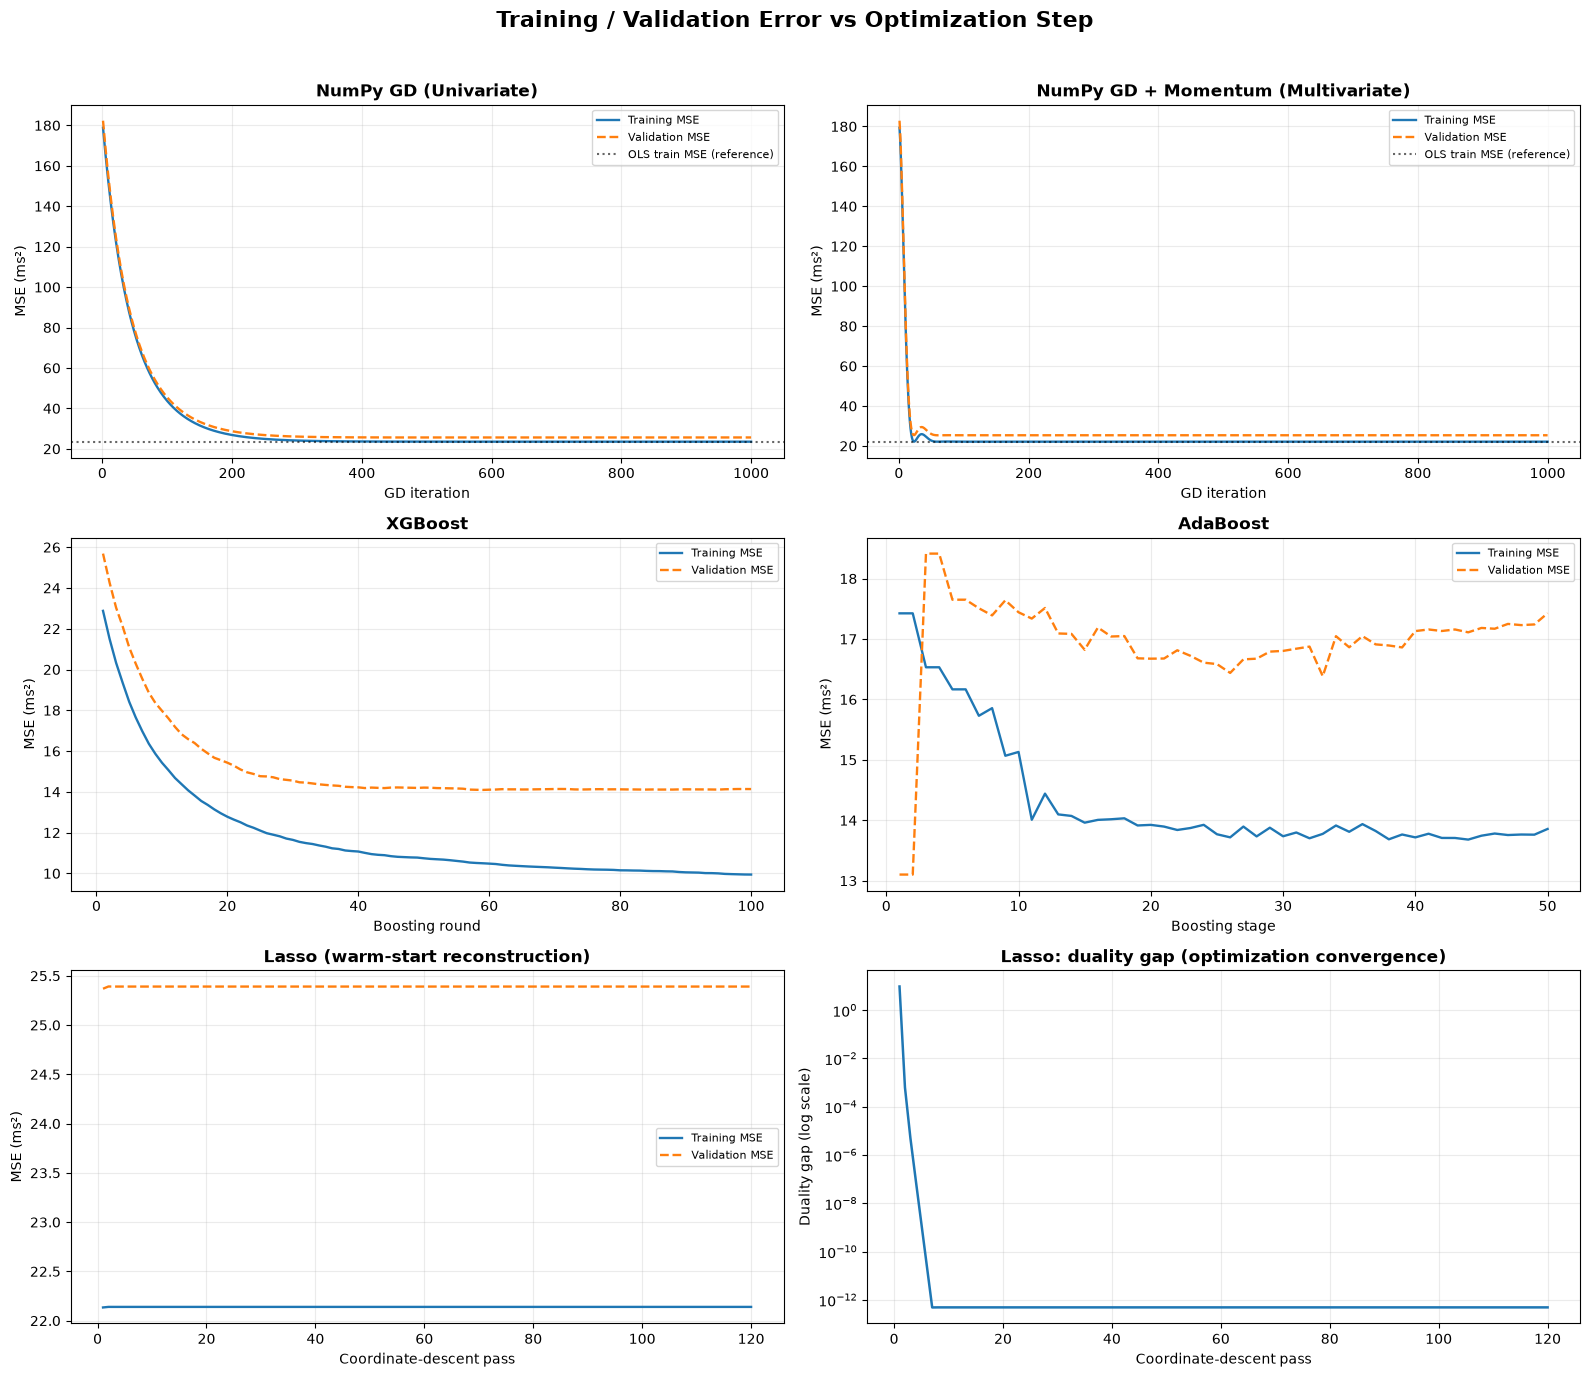

Saved: Task10_Convergence_5_Iterative_Models.png
Lasso regularized objective: initial = 11.145761 final = 11.143954
NumPy GD (Univariate)                      steps=1000  train_MSE=23.5436  val_MSE=25.6319
NumPy GD + Momentum (Multivariate)         steps=1000  train_MSE=22.1330  val_MSE=25.3474
XGBoost                                    steps= 100  train_MSE=9.9420  val_MSE=14.1355
AdaBoost                                   steps=  50  train_MSE=13.8567  val_MSE=17.4270
Lasso (warm-start reconstruction)          steps= 120  train_MSE=22.1395  val_MSE=25.3908


In [19]:
# =========================================================
# CELL 28 (NEW) - CONVERGENCE / TRAINING-STAGE CURVES
# 5 iterative models: GD, GD+Momentum, XGBoost, AdaBoost,
# and reconstructed coordinate-descent passes of Lasso.
# All models use SAME train pool and validation rows (Cell 26).
# Never evaluate final test data while building these curves.
# =========================================================
import warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import AdaBoostRegressor
from xgboost import XGBRegressor

X_tr_all = X_pool[FEATURES_MULTI].to_numpy(dtype=float)
X_va_all = X_val[FEATURES_MULTI].to_numpy(dtype=float)
y_tr_all = y_pool.to_numpy(dtype=float).ravel()
y_va_all = y_val.to_numpy(dtype=float).ravel()
X_tr_uni = X_pool[[FEATURE_BASELINE]].to_numpy(dtype=float)
X_va_uni = X_val[[FEATURE_BASELINE]].to_numpy(dtype=float)


def gd_history(X_tr, y_tr, X_va, y_va, *, lr=0.01, n_iter=1000,
               beta=None, standardize=False):
    """Full-batch GD. Log BOTH train and validation MSE per iteration."""
    if standardize:
        mu = X_tr.mean(axis=0)
        std = X_tr.std(axis=0, ddof=1) + 1e-8
        X_va = (X_va - mu) / std
        X_tr = (X_tr - mu) / std
    A_tr = np.column_stack((np.ones(len(X_tr)), X_tr))
    A_va = np.column_stack((np.ones(len(X_va)), X_va))
    theta = np.zeros((A_tr.shape[1], 1))
    velocity = np.zeros_like(theta)
    y_tr = y_tr.reshape(-1, 1)
    train_mse, valid_mse = [], []

    for _ in range(n_iter):
        residual = A_tr @ theta - y_tr
        grad = A_tr.T @ residual / len(y_tr)
        if beta is None:
            theta -= lr * grad
        else:
            velocity = beta * velocity + lr * grad
            theta -= velocity
        train_mse.append(float(np.mean((A_tr @ theta - y_tr) ** 2)))
        valid_mse.append(float(np.mean((A_va @ theta - y_va.reshape(-1, 1)) ** 2)))
    return np.asarray(train_mse), np.asarray(valid_mse)


# 1. NumPy GD - Univariate baseline
uni_train, uni_val = gd_history(
    X_tr_uni, y_tr_all, X_va_uni, y_va_all,
    lr=GD_LR, n_iter=GD_ITERATIONS
)
ols_uni = LinearRegression().fit(X_tr_uni, y_tr_all)
uni_ols_train_mse = mean_squared_error(y_tr_all, ols_uni.predict(X_tr_uni))

# 2. NumPy GD with Momentum - Multivariate
mom_train, mom_val = gd_history(
    X_tr_all, y_tr_all, X_va_all, y_va_all,
    lr=GD_LR, n_iter=GD_ITERATIONS,
    beta=MOMENTUM_BETA, standardize=True
)
ols_multi = LinearRegression().fit(X_tr_all, y_tr_all)
multi_ols_train_mse = mean_squared_error(y_tr_all, ols_multi.predict(X_tr_all))

# 3. XGBoost - native per-round evals_result (RMSE squared = MSE)
xgb_curve_model = XGBRegressor(
    n_estimators=100, learning_rate=0.08, max_depth=6,
    random_state=RANDOM_STATE, eval_metric="rmse"
)
xgb_curve_model.fit(
    X_pool[FEATURES_MULTI], y_pool,
    eval_set=[(X_pool[FEATURES_MULTI], y_pool),
              (X_val[FEATURES_MULTI], y_val)],
    verbose=False
)
xgb_log = xgb_curve_model.evals_result()
xgb_train = np.square(np.asarray(xgb_log["validation_0"]["rmse"], dtype=float))
xgb_val = np.square(np.asarray(xgb_log["validation_1"]["rmse"], dtype=float))

# 4. AdaBoost - staged predictions after each fitted boosting stage
ada_curve_model = AdaBoostRegressor(
    n_estimators=50, learning_rate=0.1, random_state=RANDOM_STATE
)
ada_curve_model.fit(X_pool[FEATURES_MULTI], y_pool)
ada_train = np.array([
    mean_squared_error(y_tr_all, pred)
    for pred in ada_curve_model.staged_predict(X_pool[FEATURES_MULTI])
])
ada_val = np.array([
    mean_squared_error(y_va_all, pred)
    for pred in ada_curve_model.staged_predict(X_val[FEATURES_MULTI])
])

# 5. Lasso - sklearn has no native per-iteration MSE history.
# Reconstruct a coordinate-descent trajectory with warm_start:
# each call to fit performs up to ONE coordinate-descent pass.
# This is NOT the loss history from Cell 25's original fit.
lasso_curve_model = Lasso(
    alpha=0.1, max_iter=1, warm_start=True,
    tol=1e-12, selection="cyclic", random_state=RANDOM_STATE
)
lasso_train, lasso_val, lasso_obj, lasso_gap = [], [], [], []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=ConvergenceWarning)
    for _ in range(120):
        lasso_curve_model.fit(X_pool[FEATURES_MULTI], y_pool)
        pred_tr = lasso_curve_model.predict(X_pool[FEATURES_MULTI])
        pred_va = lasso_curve_model.predict(X_val[FEATURES_MULTI])
        train_mse = mean_squared_error(y_tr_all, pred_tr)
        lasso_train.append(train_mse)
        lasso_val.append(mean_squared_error(y_va_all, pred_va))
        # Lasso's ACTUAL regularized training objective:
        lasso_obj.append(0.5 * train_mse + 0.1 * np.abs(lasso_curve_model.coef_).sum())
        lasso_gap.append(max(1e-14, float(np.asarray(lasso_curve_model.dual_gap_).item())))
lasso_train, lasso_val = np.array(lasso_train), np.array(lasso_val)

# Plot each model on its own axes; iteration and boosting round
# are different units and must NOT be overlaid as one series.
curves = [
    ("NumPy GD (Univariate)", uni_train, uni_val, "GD iteration", uni_ols_train_mse),
    ("NumPy GD + Momentum (Multivariate)", mom_train, mom_val,
     "GD iteration", multi_ols_train_mse),
    ("XGBoost", xgb_train, xgb_val, "Boosting round", None),
    ("AdaBoost", ada_train, ada_val, "Boosting stage", None),
    ("Lasso (warm-start reconstruction)", lasso_train, lasso_val,
     "Coordinate-descent pass", None)
]
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
for ax, (name, tr, va, x_label, reference) in zip(axes.ravel(), curves):
    epochs = np.arange(1, len(tr) + 1)
    ax.plot(epochs, tr, label="Training MSE", linewidth=1.7)
    ax.plot(epochs, va, label="Validation MSE", linewidth=1.7, linestyle="--")
    if reference is not None:
        ax.axhline(reference, color="black", alpha=0.6, linestyle=":",
                   label="OLS train MSE (reference)")
    ax.set_title(name, fontweight="bold")
    ax.set_xlabel(x_label)
    ax.set_ylabel("MSE (ms²)")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)

# Lasso-specific convergence diagnostic (dual gap), unlike MSE,
# measures progress toward the regularized optimization optimum.
ax_gap = axes.ravel()[-1]
ax_gap.semilogy(np.arange(1, len(lasso_gap) + 1), lasso_gap, linewidth=1.8)
ax_gap.set_title("Lasso: duality gap (optimization convergence)", fontweight="bold")
ax_gap.set_xlabel("Coordinate-descent pass")
ax_gap.set_ylabel("Duality gap (log scale)")
ax_gap.grid(alpha=0.25)
fig.suptitle("Training / Validation Error vs Optimization Step",
             fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.965))
convergence_output = "Task10_Convergence_5_Iterative_Models.png"
fig.savefig(convergence_output, dpi=300, bbox_inches="tight")
fig.savefig("figures/" + convergence_output, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", convergence_output)
print("Lasso regularized objective: initial =",
      round(lasso_obj[0], 6), "final =", round(lasso_obj[-1], 6))
for name, tr, va, _, _ in curves:
    print(f"{name:42s} steps={len(tr):4d}  "
          f"train_MSE={tr[-1]:.4f}  val_MSE={va[-1]:.4f}")


In [20]:
import os

required = [
    "figures/scatter_plot.png",
    "figures/cost_surface.png",
    "figures/cost_contour.png",
    "figures/convergence.png",
    "figures/regression_line.png",
    "figures/residual_plot.png",
]
supporting = [
    "figures/eda_distributions.png",
    "figures/Task2_Compare_4_Features_ScatterPlots.png",
    "phan10.png",
    "figures/Task10_Training_Size_Performance_Bar_Chart_9_Models.png",
    "figures/Task10_Convergence_5_Iterative_Models.png",
]

print("=== KIỂM TRA HÌNH ẢNH ĐẦU RA ===")
missing = []
for name in required + supporting:
    ok = os.path.exists(name)
    size = os.path.getsize(name) if ok else 0
    print(f"{'OK ' if ok else 'MISS'} {name:65s} {size:>10,} bytes")
    if not ok:
        missing.append(name)

assert not missing, f"Thiếu hình: {missing}"
print("\nTẤT CẢ HÌNH ẢNH BẮT BUỘC ĐÃ ĐƯỢC TẠO THÀNH CÔNG.")


=== KIỂM TRA HÌNH ẢNH ĐẦU RA ===
OK  figures/scatter_plot.png                                             465,471 bytes
OK  figures/cost_surface.png                                             899,997 bytes
OK  figures/cost_contour.png                                             279,732 bytes
OK  figures/convergence.png                                              135,564 bytes
OK  figures/regression_line.png                                          199,267 bytes
OK  figures/residual_plot.png                                            155,861 bytes
OK  figures/eda_distributions.png                                        157,951 bytes
OK  figures/Task2_Compare_4_Features_ScatterPlots.png                    465,471 bytes
OK  phan10.png                                                           199,267 bytes
OK  figures/Task10_Training_Size_Performance_Bar_Chart_9_Models.png    1,000,563 bytes
OK  figures/Task10_Convergence_5_Iterative_Models.png                    612,571 bytes

TẤT CẢ HÌ